# Nhận diện chữ số La Mã với VGG16 — PyTorch

Notebook huấn luyện **local bằng PyTorch**, chạy GPU native trên Windows (không cần WSL). Bài toán phân loại 10 lớp: `i, ii, iii, iv, v, vi, vii, viii, ix, x`.

### Nguồn dữ liệu
- Nếu có `data/train` + `data/val` (bộ đầy đủ ~2.900 ảnh), notebook dùng làm train/validation.
- Nếu chưa giải nén, notebook tự giải nén `original/data.tar.gz`.
- `label_book/` (52 ảnh) dùng làm **test set độc lập**.
- Nếu chỉ có `label_book/`, notebook vẫn chạy nhưng chia stratified 70/15/15 và in cảnh báo.

### Điểm quan trọng
**KHÔNG lật ngang/dọc ảnh chữ số La Mã** vì `IV ↔ VI`, `IX ↔ XI`… sẽ đổi nghĩa. Notebook chỉ xoay nhẹ, zoom, dịch chuyển, đổi tương phản/độ sáng.

### Kết quả tạo ra
- `reports/` : biểu đồ + CSV phân tích lỗi
- `models/` : `vgg16_roman_best.pt`, `vgg16_roman_final.pt`
- `dataset_index.csv` : index ảnh, kích thước, độ sáng, MD5

### Mục lục
1. Cài đặt & cấu hình
2. Tìm / giải nén dữ liệu, audit
3. EDA: phân bố lớp, kích thước, độ sáng, gallery
4. Augmentation an toàn & Dataset/DataLoader
5. Xây dựng VGG16
6. Training loop, phase 1 & phase 2
7. Đánh giá: metrics, confusion matrix, calibration, lỗi
8. Grad-CAM & error analysis
9. Lưu model, dự đoán ảnh mới
10. Test đánh giá độc lập + checklist cải thiện

## 0. Cài đặt thư viện

Chạy 1 lần. Với RTX 3060 Ti, dùng wheel CUDA 12.8:

```python
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128
%pip install scikit-learn seaborn pandas matplotlib pillow jupyterlab
```

Nếu máy chỉ có CPU, bỏ `--index-url` và cài bản mặc định.

In [1]:
# Bỏ dấu # nếu chưa cài:
# %pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128
# %pip install scikit-learn seaborn pandas matplotlib pillow jupyterlab

## 1. Import & cấu hình

Các tham số quan trọng:
- `IMG_SIZE = (128, 128)` — cân bằng tốc độ/chất lượng. Có thể thử `160` hoặc `224` nếu VRAM cho phép.
- `BATCH_SIZE = 32` — RTX 3060 Ti 8GB nên bắt đầu từ 32.
- `MIXED_PRECISION = True` — dùng AMP trên GPU để nhanh hơn và tiết kiệm VRAM.
- `NUM_WORKERS = 0` — an toàn trên Windows; có thể tăng lên 2–4 nếu chạy Linux/WSL.

In [2]:

import os
import json
import copy
import time
import random
import hashlib
import tarfile
import warnings
import contextlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
from torchvision.models import VGG16_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    top_k_accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

# ------------------------------------------------------------------
# ĐƯỜNG DẪN
# ------------------------------------------------------------------
BASE_DIR = Path.cwd()
# Nếu mở notebook từ thư mục khác, sửa cứng đường dẫn:
# BASE_DIR = Path(r"C:\Users\Administrator\Downloads\deeplearningai-data-centric-competition-main\deeplearningai-data-centric-competition-main")

LABEL_BOOK_DIR = BASE_DIR / "label_book"
REPORT_DIR = BASE_DIR / "reports"
MODEL_DIR = BASE_DIR / "models"
REPORT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

# ------------------------------------------------------------------
# CẤU HÌNH
# ------------------------------------------------------------------
CLASS_NAMES = ["i", "ii", "iii", "iv", "v", "vi", "vii", "viii", "ix", "x"]
NUM_CLASSES = len(CLASS_NAMES)

IMG_SIZE = (160, 160)          # (width, height)
BATCH_SIZE = 24
SEED = 42

VAL_FRACTION = 0.15
RESPLIT_TRAIN_VAL = True      # gộp train+val gốc rồi chia stratified lại

EPOCHS_HEAD = 25              # phase 1: đóng băng VGG16 features
EPOCHS_FINETUNE = 20          # phase 2: mở block5
LR_HEAD = 1e-3
LR_FINETUNE = 3e-5
WEIGHT_DECAY = 1e-4
PATIENCE = 7

USE_PRETRAINED = True
MIXED_PRECISION = False
NUM_WORKERS = 0

BEST_MODEL_PATH = MODEL_DIR / "vgg16_roman_best.pt"
FINAL_MODEL_PATH = MODEL_DIR / "vgg16_roman_final.pt"

# ImageNet normalization (PyTorch dùng RGB, không phải BGR như TensorFlow)
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

# ------------------------------------------------------------------
# DEVICE / SEED
# ------------------------------------------------------------------
def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    props = torch.cuda.get_device_properties(0)
    print("GPU :", torch.cuda.get_device_name(0))
    print("VRAM:", round(props.total_memory / 1024**3, 1), "GB")
    print("CUDA:", torch.version.cuda)
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    print("Device: Apple MPS")
else:
    DEVICE = torch.device("cpu")
    print("Device: CPU — train sẽ chậm hơn nhiều.")

USE_CUDA = DEVICE.type == "cuda"
USE_AMP = MIXED_PRECISION and USE_CUDA

print("PyTorch   :", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device    :", DEVICE)
print("Mixed precision (AMP):", USE_AMP)
print("BASE_DIR  :", BASE_DIR)

GPU : NVIDIA GeForce RTX 3060 Ti
VRAM: 8.0 GB
CUDA: 12.8
PyTorch   : 2.11.0+cu128
Torchvision: 0.26.0+cu128
Device    : cuda
Mixed precision (AMP): False
BASE_DIR  : c:\Users\Administrator\Downloads\deeplearningai-data-centric-competition-main\deeplearningai-data-centric-competition-main


## 2. Tìm dữ liệu, giải nén và audit

Cell này tự tìm `data/train` + `data/val`, tự giải nén `original/data.tar.gz` nếu cần, loại ảnh hỏng, ảnh trùng MD5 và leakage train/test, rồi chia stratified train/val.

In [3]:
def find_data_root(base: Path):
    for candidate in [base / "data", base]:
        if (candidate / "train").is_dir():
            return candidate
    return None


DATA_ROOT = find_data_root(BASE_DIR)

if DATA_ROOT is None:
    tar_path = BASE_DIR / "original" / "data.tar.gz"
    if tar_path.exists():
        print("Chưa thấy data/train. Đang giải nén", tar_path, "...")
        with tarfile.open(tar_path) as tar:
            tar.extractall(BASE_DIR)
        DATA_ROOT = find_data_root(BASE_DIR)
        print("Đã giải nén xong.")
    else:
        print("Không tìm thấy data.tar.gz — sẽ dùng label_book (rất ít ảnh).")

print("DATA_ROOT :", DATA_ROOT if DATA_ROOT else "None (chỉ dùng label_book)")
print("LABEL_BOOK:", LABEL_BOOK_DIR, "| tồn tại:", LABEL_BOOK_DIR.is_dir())

DATA_ROOT : c:\Users\Administrator\Downloads\deeplearningai-data-centric-competition-main\deeplearningai-data-centric-competition-main\data
LABEL_BOOK: c:\Users\Administrator\Downloads\deeplearningai-data-centric-competition-main\deeplearningai-data-centric-competition-main\label_book | tồn tại: True


In [4]:
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}


def file_md5(path: Path, chunk_size=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def scan_folder(folder: Path, split: str):
    rows, bad = [], []
    if not folder or not folder.is_dir():
        return pd.DataFrame(rows), bad
    for class_name in CLASS_NAMES:
        class_dir = folder / class_name
        if not class_dir.is_dir():
            continue
        for path in sorted(class_dir.rglob("*")):
            if not path.is_file() or path.suffix.lower() not in IMG_EXTS:
                continue
            try:
                with Image.open(path) as im:
                    im.verify()
                with Image.open(path) as im:
                    width, height = im.size
                    mode = im.mode
                    gray = np.asarray(im.convert("L"), dtype=np.float32)
                    brightness = float(gray.mean())
                    contrast = float(gray.std())
                rows.append({
                    "path": str(path.resolve()),
                    "label": CLASS_NAMES.index(class_name),
                    "class_name": class_name,
                    "split": split,
                    "width": width,
                    "height": height,
                    "aspect": width / height,
                    "mode": mode,
                    "brightness": brightness,
                    "contrast": contrast,
                    "md5": file_md5(path),
                })
            except Exception as exc:
                bad.append((str(path), str(exc)))
    return pd.DataFrame(rows), bad


bad_files = []
if DATA_ROOT is not None:
    pool_df, bad_train = scan_folder(DATA_ROOT / "train", "train")
    val_orig_df, bad_val = scan_folder(DATA_ROOT / "val", "val")
    pool_df = pd.concat([pool_df, val_orig_df], ignore_index=True)
    bad_files += bad_train + bad_val
    test_df, bad_test = scan_folder(LABEL_BOOK_DIR, "test")
    bad_files += bad_test
else:
    pool_df, bad_pool = scan_folder(LABEL_BOOK_DIR, "train")
    bad_files += bad_pool
    test_df = pd.DataFrame()

n_raw_pool, n_raw_test = len(pool_df), len(test_df)

# --- loại ảnh trùng hoàn toàn (MD5) ---
pool_df = pool_df.drop_duplicates("md5", keep="first").reset_index(drop=True)
test_df = test_df.drop_duplicates("md5", keep="first").reset_index(drop=True)
dup_pool = n_raw_pool - len(pool_df)

# --- chống leakage: ảnh test không được xuất hiện trong train ---
test_hashes = set(test_df["md5"]) if len(test_df) else set()
leak_count = int(pool_df["md5"].isin(test_hashes).sum())
if leak_count:
    pool_df = pool_df[~pool_df["md5"].isin(test_hashes)].reset_index(drop=True)

# --- chia train/val ---
if len(test_df) == 0 and len(pool_df) > 0:
    print("Không có test set riêng — chia stratified 70/15/15 từ dữ liệu hiện có.")
    train_df, temp_df = train_test_split(
        pool_df, test_size=0.30, stratify=pool_df["label"], random_state=SEED
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
    )
elif RESPLIT_TRAIN_VAL:
    train_df, val_df = train_test_split(
        pool_df, test_size=VAL_FRACTION, stratify=pool_df["label"], random_state=SEED
    )
else:
    train_df = pool_df[pool_df["split"] == "train"].copy()
    val_df = pool_df[pool_df["split"] == "val"].copy()

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

df_all = pd.concat([train_df, val_df, test_df], ignore_index=True)
df_all.to_csv(BASE_DIR / "dataset_index.csv", index=False)

print("=" * 62)
print(f"Ảnh quét ban đầu : pool={n_raw_pool}, test={n_raw_test}")
print(f"Ảnh hỏng bị bỏ   : {len(bad_files)}")
print(f"Trùng trong pool : {dup_pool} (đã loại theo MD5)")
print(f"Leakage train/test: {leak_count}")
print(f"Train / Val / Test: {len(train_df)} / {len(val_df)} / {len(test_df)}")
print("=" * 62)

if len(pool_df) < 200:
    print("CẢNH BÁO: dữ liệu train rất ít. Hãy giải nén original/data.tar.gz hoặc bổ sung ảnh.")
if bad_files:
    display(pd.DataFrame(bad_files, columns=["file", "error"]).head(20))

Ảnh quét ban đầu : pool=2880, test=52
Ảnh hỏng bị bỏ   : 0
Trùng trong pool : 49 (đã loại theo MD5)
Leakage train/test: 3
Train / Val / Test: 2403 / 425 / 52


In [5]:
summary = (
    df_all.groupby(["class_name", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(CLASS_NAMES)
)
summary = summary[[c for c in ["train", "val", "test"] if c in summary.columns]]

print("Số ảnh theo lớp:")
display(summary)

counts = summary["train"] if "train" in summary else summary.sum(axis=1)
print(f"Tỉ lệ mất cân bằng train (max/min) = {counts.max() / max(counts.min(), 1):.2f}")
print(f"Lớp ít nhất: {counts.idxmin()} ({counts.min()} ảnh) | nhiều nhất: {counts.idxmax()} ({counts.max()} ảnh)")

Số ảnh theo lớp:


split,train,val,test
class_name,,,
i,284,50,5
ii,202,36,5
iii,217,39,6
iv,308,54,5
v,232,41,6
vi,223,40,5
vii,223,40,5
viii,240,42,5
ix,263,46,5


Tỉ lệ mất cân bằng train (max/min) = 1.52
Lớp ít nhất: ii (202 ảnh) | nhiều nhất: iv (308 ảnh)


## 3. EDA — biểu đồ thống kê dữ liệu

### 3.1. Phân bố ảnh theo lớp và split

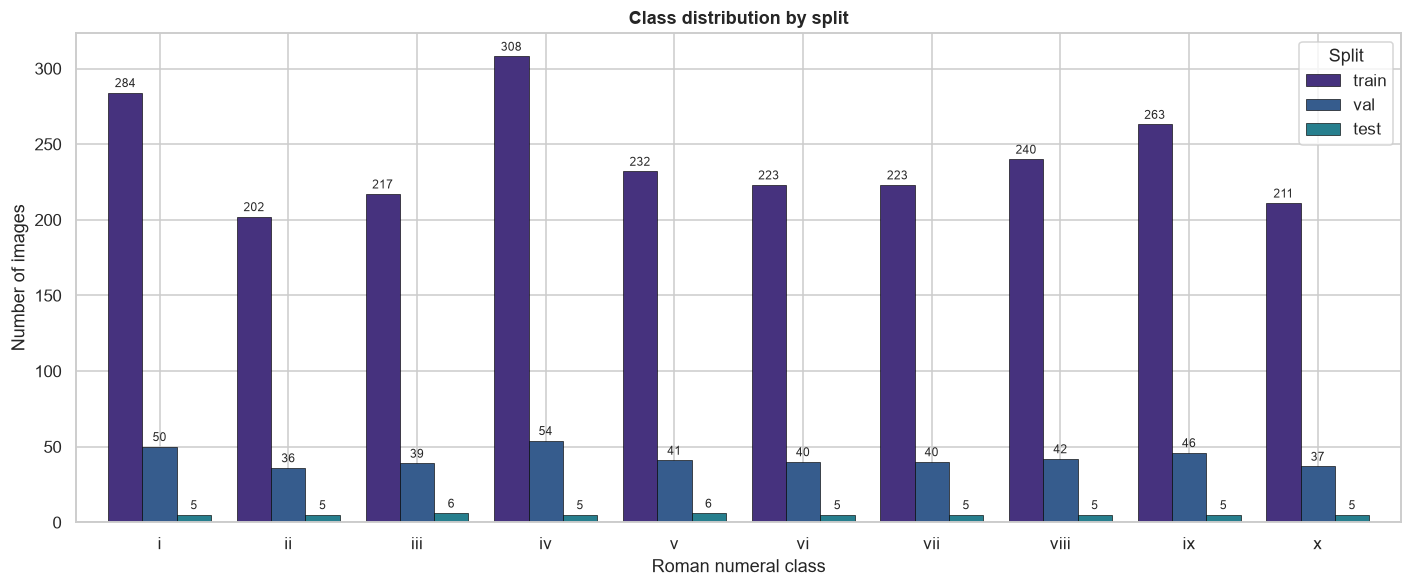

In [6]:
fig, ax = plt.subplots(figsize=(13, 5.5))
summary.plot(kind="bar", ax=ax, width=0.8, edgecolor="black", linewidth=0.4)
ax.set_title("Class distribution by split")
ax.set_xlabel("Roman numeral class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)
for container in ax.containers:
    ax.bar_label(container, fontsize=8, padding=2)
ax.legend(title="Split")
plt.tight_layout()
plt.savefig(REPORT_DIR / "01_class_distribution.png", bbox_inches="tight")
plt.show()

### 3.2. Kích thước ảnh, tỉ lệ khung và độ sáng

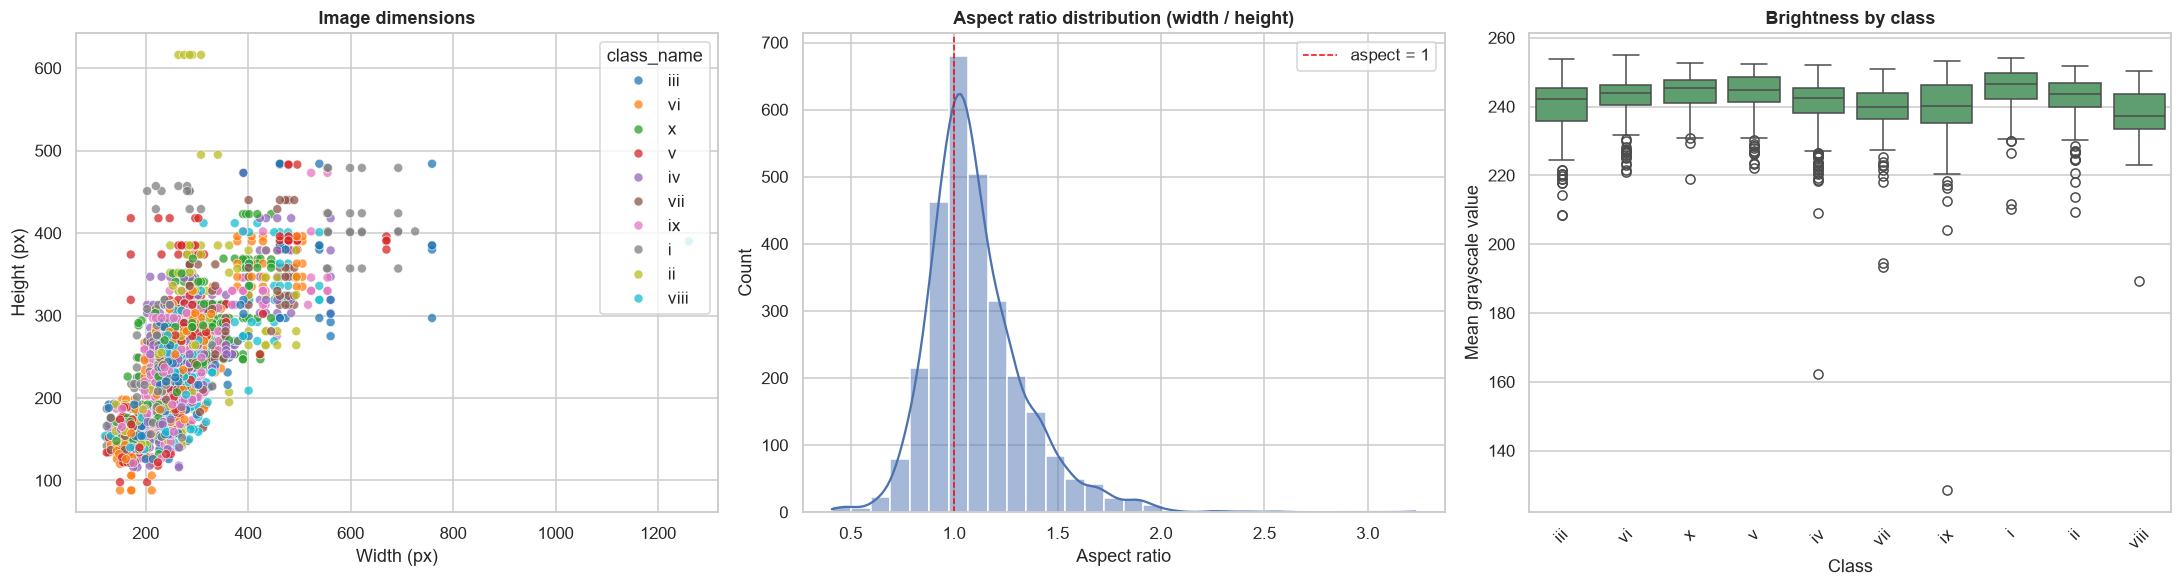

             count        mean        std         min         25%         50%  \
width       2880.0  279.150347  83.366564  121.000000  237.000000  264.000000   
height      2880.0  257.257986  66.064930   88.000000  219.000000  255.000000   
aspect      2880.0    1.105318   0.235207    0.409091    0.959259    1.061776   
brightness  2880.0  241.592102   7.513145  128.436630  237.777554  243.048126   
contrast    2880.0   50.892439  12.650356    0.000000   42.529592   50.259792   

                   75%          max  
width       292.500000  1260.000000  
height      291.000000   616.000000  
aspect        1.215239     3.230769  
brightness  246.597229   255.000000  
contrast     58.797469   106.059860  


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

sns.scatterplot(
    data=df_all, x="width", y="height", hue="class_name",
    palette="tab10", s=35, alpha=0.75, ax=axes[0], legend="brief"
)
axes[0].set_title("Image dimensions")
axes[0].set_xlabel("Width (px)")
axes[0].set_ylabel("Height (px)")

sns.histplot(df_all["aspect"], bins=30, kde=True, color="#4C72B0", ax=axes[1])
axes[1].axvline(1.0, color="red", ls="--", lw=1, label="aspect = 1")
axes[1].set_title("Aspect ratio distribution (width / height)")
axes[1].set_xlabel("Aspect ratio")
axes[1].legend()

sns.boxplot(data=df_all, x="class_name", y="brightness", ax=axes[2], color="#55A868")
axes[2].set_title("Brightness by class")
axes[2].set_xlabel("Class")
axes[2].set_ylabel("Mean grayscale value")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(REPORT_DIR / "02_image_geometry_brightness.png", bbox_inches="tight")
plt.show()

print(df_all[["width", "height", "aspect", "brightness", "contrast"]].describe().T)

### 3.3. Gallery mẫu

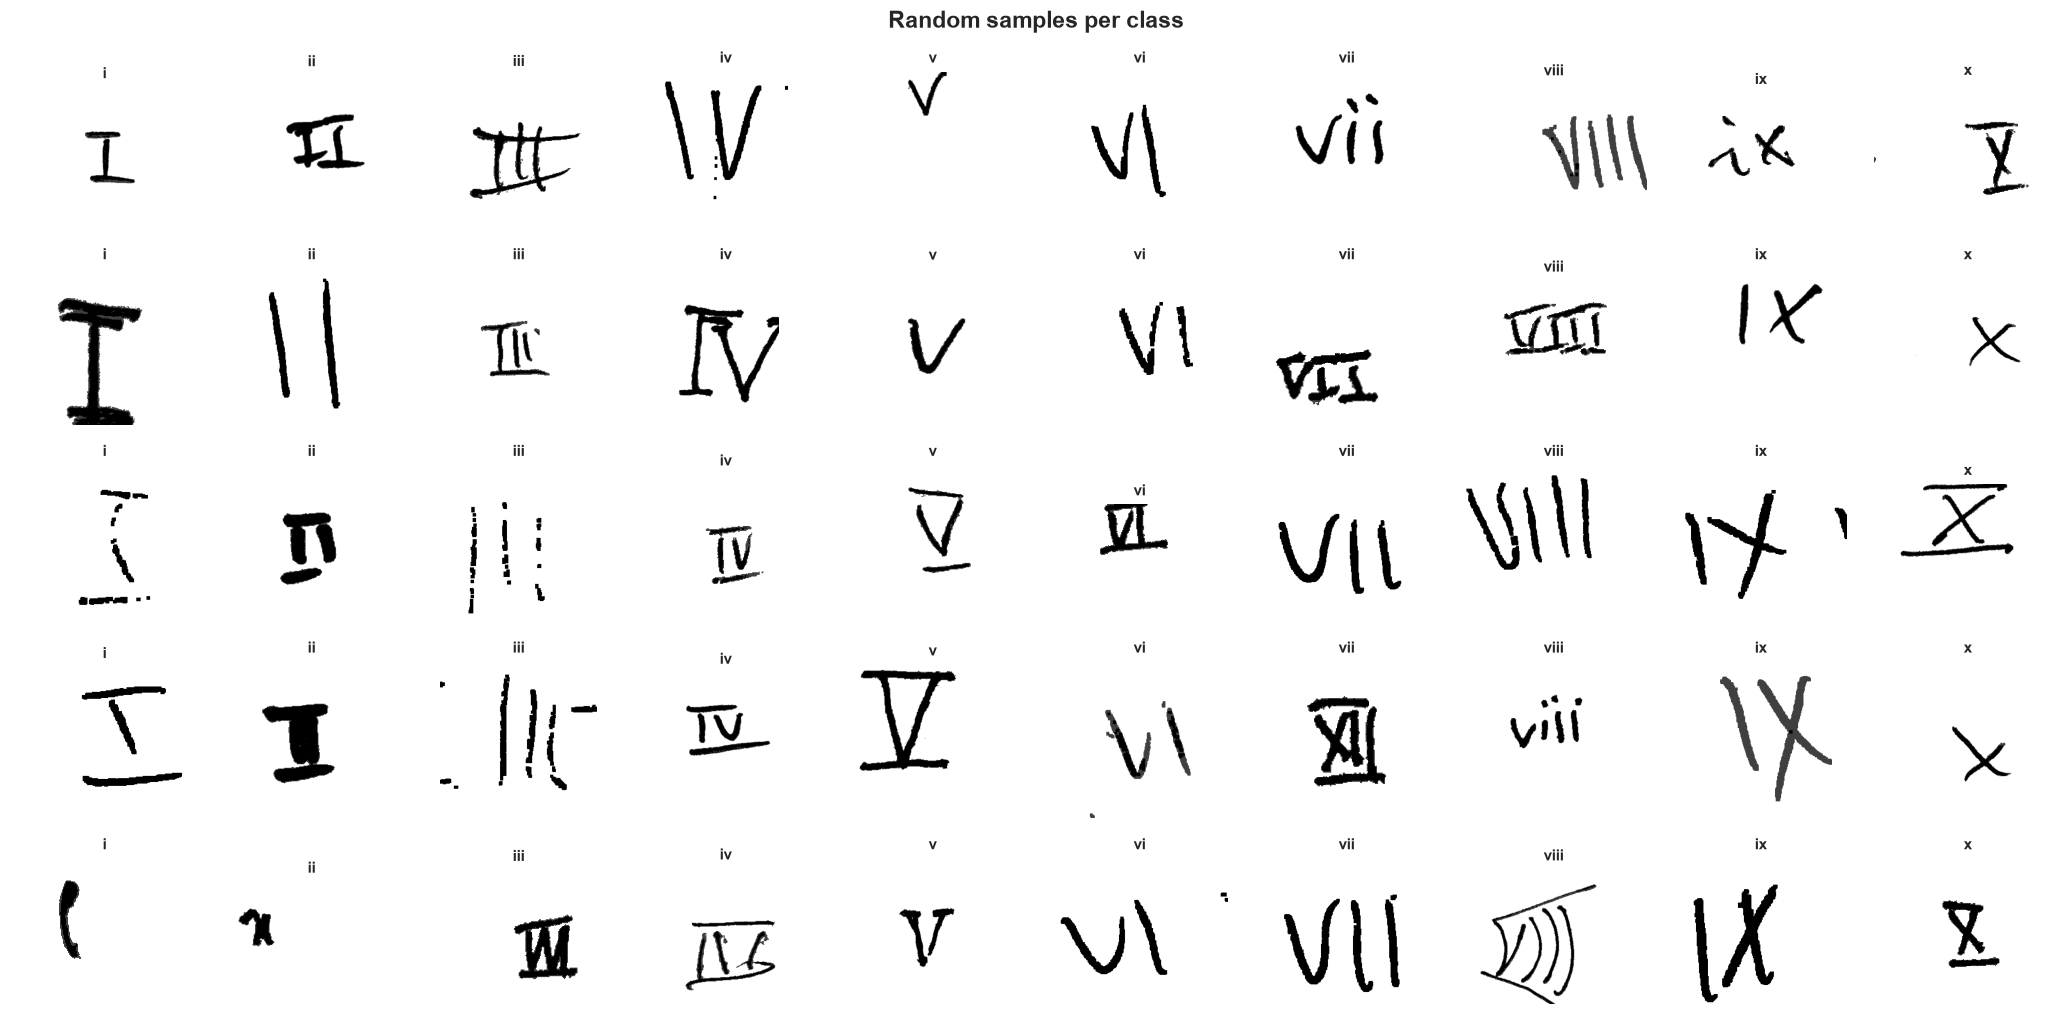

In [8]:
def show_gallery(frame, per_class=5, seed=SEED):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(
        nrows=per_class, ncols=NUM_CLASSES,
        figsize=(1.9 * NUM_CLASSES, 1.9 * per_class)
    )
    axes = np.atleast_2d(axes)
    for col, class_name in enumerate(CLASS_NAMES):
        subset = frame[frame["class_name"] == class_name]
        if len(subset) == 0:
            continue
        chosen = subset.iloc[rng.choice(len(subset), size=min(per_class, len(subset)), replace=False)]
        for row, (_, record) in enumerate(chosen.iterrows()):
            with Image.open(record["path"]) as im:
                axes[row, col].imshow(im.convert("L"), cmap="gray")
            axes[row, col].axis("off")
            axes[row, col].set_title(class_name, fontsize=10)
    for row in range(axes.shape[0]):
        for col in range(axes.shape[1]):
            if not axes[row, col].has_data():
                axes[row, col].axis("off")
    fig.suptitle("Random samples per class", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(REPORT_DIR / "03_sample_gallery.png", bbox_inches="tight")
    plt.show()


show_gallery(df_all, per_class=5)

## 4. Augmentation an toàn & Dataset/DataLoader

- ✅ Xoay nhẹ ±10°, zoom/dịch chuyển nhẹ, đổi tương phản/độ sáng.
- ❌ **Không flip ngang/dọc**, không xoay 90°/180°.
- Ảnh grayscale được nhân bản thành 3 kênh để dùng VGG16 pretrained.
- Chuẩn hoá theo ImageNet: mean `(0.485, 0.456, 0.406)`, std `(0.229, 0.224, 0.225)`.

In [9]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE[1], IMG_SIZE[0])),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(degrees=10, fill=255),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.06, 0.06),
        scale=(0.90, 1.10),
        fill=255,
    ),
    transforms.ColorJitter(brightness=0.10, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE[1], IMG_SIZE[0])),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

print("Train transform:")
print(train_transform)
print("\nVal/Test transform:")
print(val_transform)

Train transform:
Compose(
    Resize(size=(160, 160), interpolation=bilinear, max_size=None, antialias=True)
    Grayscale(num_output_channels=3)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=255)
    RandomAffine(degrees=[0.0, 0.0], translate=(0.06, 0.06), scale=(0.9, 1.1), fill=255)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.85, 1.15), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)

Val/Test transform:
Compose(
    Resize(size=(160, 160), interpolation=bilinear, max_size=None, antialias=True)
    Grayscale(num_output_channels=3)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


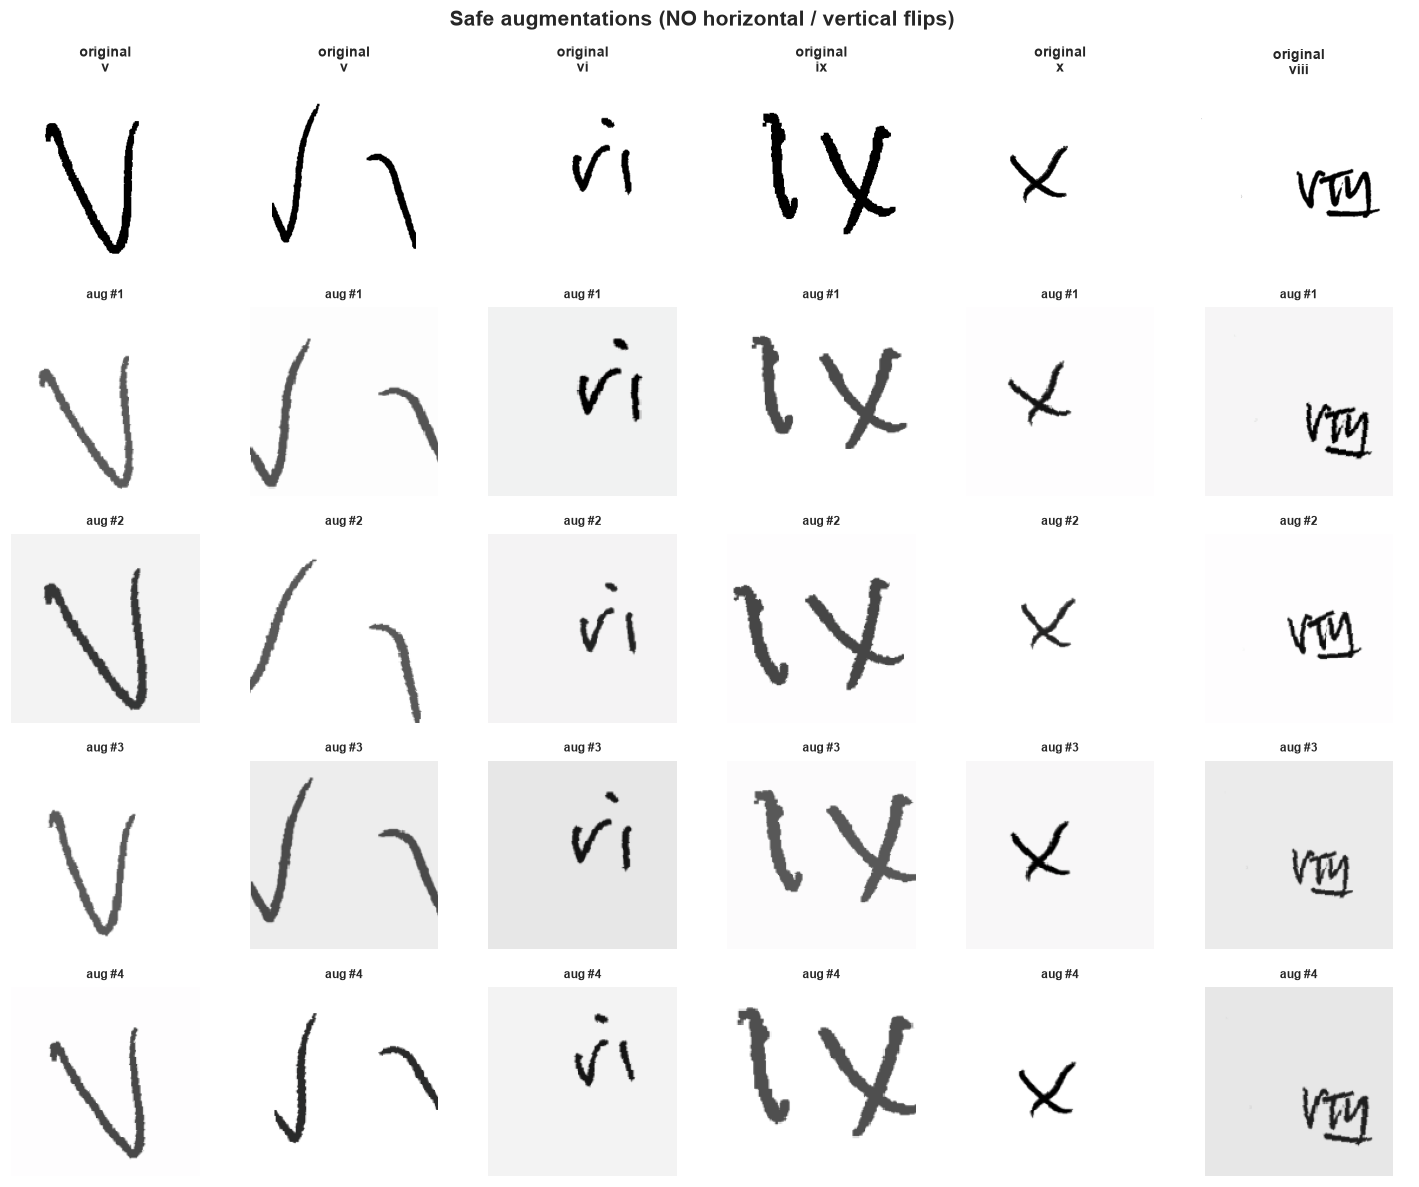

In [10]:
def denormalize(tensor):
    mean = torch.tensor(MEAN, dtype=tensor.dtype).view(3, 1, 1)
    std = torch.tensor(STD, dtype=tensor.dtype).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1)


def show_augmentations(frame, n=6, n_aug=4):
    sample = frame.sample(n=min(n, len(frame)), random_state=SEED)
    fig, axes = plt.subplots(n_aug + 1, len(sample), figsize=(2.2 * len(sample), 2.2 * (n_aug + 1)))
    axes = np.atleast_2d(axes)
    for col, (_, record) in enumerate(sample.iterrows()):
        with Image.open(record["path"]) as im:
            image = im.convert("L")
            axes[0, col].imshow(np.asarray(image), cmap="gray")
        axes[0, col].set_title(f"original\n{record['class_name']}", fontsize=9)
        axes[0, col].axis("off")
        for row in range(1, n_aug + 1):
            augmented = train_transform(image)
            augmented = denormalize(augmented).permute(1, 2, 0).numpy()
            axes[row, col].imshow(augmented)
            axes[row, col].set_title(f"aug #{row}", fontsize=8)
            axes[row, col].axis("off")
    fig.suptitle("Safe augmentations (NO horizontal / vertical flips)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(REPORT_DIR / "04_augmentation_examples.png", bbox_inches="tight")
    plt.show()


show_augmentations(train_df if len(train_df) else df_all)

### 4.1. Dataset & DataLoader

In [11]:
class RomanDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.paths = frame["path"].tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert("L")
            if self.transform is not None:
                image = self.transform(image)
        return image, torch.tensor(self.labels[index], dtype=torch.long)


train_dataset = RomanDataset(train_df, train_transform)
val_dataset = RomanDataset(val_df, val_transform)
test_dataset = RomanDataset(test_df, val_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=USE_CUDA,
    drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=USE_CUDA,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=USE_CUDA,
    persistent_workers=NUM_WORKERS > 0,
)

images, labels = next(iter(train_loader))
print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))
print("Batch shape  :", tuple(images.shape), "| labels:", tuple(labels.shape))
print("Pixel range  :", float(images.min()), "→", float(images.max()))

# class weights cho dữ liệu mất cân bằng
present_classes = np.unique(train_df["label"].values)
weights = compute_class_weight(
    class_weight="balanced",
    classes=present_classes,
    y=train_df["label"].values,
)
weight_array = np.ones(NUM_CLASSES, dtype=np.float32)
for c, w in zip(present_classes, weights):
    weight_array[int(c)] = float(w)

class_weights = torch.tensor(weight_array, dtype=torch.float32, device=DEVICE)
print("Class weights:", {CLASS_NAMES[i]: round(float(w), 3) for i, w in enumerate(class_weights.cpu())})

Train batches: 100
Val batches  : 18
Test batches : 3
Batch shape  : (24, 3, 160, 160) | labels: (24,)
Pixel range  : -2.1179039478302 → 2.640000104904175
Class weights: {'i': 0.846, 'ii': 1.19, 'iii': 1.107, 'iv': 0.78, 'v': 1.036, 'vi': 1.078, 'vii': 1.078, 'viii': 1.001, 'ix': 0.914, 'x': 1.139}


## 5. Xây dựng VGG16

- Dùng `torchvision.models.vgg16` với ImageNet weights.
- Bỏ classifier gốc, thêm `AdaptiveAvgPool2d(1x1)` + MLP nhỏ.
- **Phase 1:** đóng băng toàn bộ convolution features, chỉ train classifier.
- **Phase 2:** mở `block5` (các layer từ `features[24:]`) để fine-tune với LR nhỏ.

In [12]:
class VGG16Roman(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        weights = VGG16_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = torchvision.models.vgg16(weights=weights)
        self.features = backbone.features
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.50),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.30),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


try:
    model = VGG16Roman(num_classes=NUM_CLASSES, pretrained=USE_PRETRAINED).to(DEVICE)
    print("Đã tải VGG16 ImageNet weights." if USE_PRETRAINED else "VGG16 random init.")
except Exception as exc:
    print("Không tải được ImageNet weights, train from scratch. Lỗi:", exc)
    model = VGG16Roman(num_classes=NUM_CLASSES, pretrained=False).to(DEVICE)

# Phase 1: đóng băng features
for param in model.features[17:].parameters():   # block4 + block5, thay vì [24:]
    param.requires_grad = True

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params     : {total_params:,}")
print(f"Trainable params : {trainable_params:,}")
print(f"Tỉ lệ trainable  : {trainable_params / total_params:.1%}")
print(model)

Đã tải VGG16 ImageNet weights.
Total params     : 15,112,778
Trainable params : 15,112,778
Tỉ lệ trainable  : 100.0%
VGG16Roman(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), st

## 6. Training loop, checkpoint & early stopping

PyTorch không có `model.fit`, nên notebook định nghĩa training loop rõ ràng:
- AMP (`torch.amp.autocast` + `GradScaler`) khi có GPU.
- `CrossEntropyLoss` có class weights.
- `ReduceLROnPlateau` giảm LR khi val loss đi ngang.
- Lưu checkpoint tốt nhất theo `val_accuracy`.
- Early stopping theo `val_loss`.

In [13]:
HISTORY = {
    "phase": [],
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "lr": [],
}
BEST_VAL_ACC = -1.0


def load_checkpoint(path, map_location=DEVICE):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def make_scaler():
    if not USE_AMP:
        return None
    try:
        return torch.amp.GradScaler("cuda", enabled=True)
    except (TypeError, AttributeError):
        return torch.cuda.amp.GradScaler(enabled=True)


@contextlib.contextmanager
def autocast_ctx():
    if not USE_AMP:
        yield
    else:
        try:
            with torch.amp.autocast("cuda", enabled=True):
                yield
        except (TypeError, AttributeError):
            with torch.cuda.amp.autocast(enabled=True):
                yield


def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss, total_correct, total_n = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.set_grad_enabled(is_train):
            with autocast_ctx():
                logits = model(images)
                loss = criterion(logits, labels)

            if is_train:
                optimizer.zero_grad(set_to_none=True)
                if scaler is not None:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_n += labels.size(0)

    return total_loss / total_n, total_correct / total_n


def fit(model, train_loader, val_loader, epochs, lr, phase_name, patience=PATIENCE):
    global BEST_VAL_ACC

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
    params = [p for p in model.parameters() if p.requires_grad]
    if not params:
        raise RuntimeError("Không có parameter nào cần train.")

    optimizer = torch.optim.Adam(params, lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-7
    )
    scaler = make_scaler()

    hist = {"phase": [], "train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
    best_phase_loss = float("inf")
    wait = 0

    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        hist["phase"].append(phase_name)
        hist["train_loss"].append(train_loss)
        hist["val_loss"].append(val_loss)
        hist["train_acc"].append(train_acc)
        hist["val_acc"].append(val_acc)
        hist["lr"].append(current_lr)
        for key in ["phase", "train_loss", "val_loss", "train_acc", "val_acc", "lr"]:
            HISTORY[key].append(hist[key][-1])

        improved = val_acc > BEST_VAL_ACC
        if improved:
            BEST_VAL_ACC = val_acc
            torch.save({
                "model_state_dict": model.state_dict(),
                "val_accuracy": float(val_acc),
                "epoch": epoch,
                "phase": phase_name,
                "class_names": CLASS_NAMES,
                "image_size": list(IMG_SIZE),
            }, BEST_MODEL_PATH)
            marker = "  *best saved*"
        else:
            marker = ""

        elapsed = time.time() - start
        print(
            f"[{phase_name}] {epoch:02d}/{epochs} | "
            f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
            f"val loss {val_loss:.4f} acc {val_acc:.4f} | "
            f"lr {current_lr:.2e} | {elapsed:.1f}s{marker}"
        )

        if val_loss < best_phase_loss - 1e-4:
            best_phase_loss = val_loss
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping ở epoch {epoch} (không cải thiện val_loss {patience} epoch).")
                break

    print(f"Best val accuracy ({phase_name}): {BEST_VAL_ACC:.4f}")
    return hist


def plot_history(history, title="Training history", fname="05_training_history.png"):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))

    axes[0].plot(epochs, history["train_loss"], label="train", marker="o", ms=3)
    axes[0].plot(epochs, history["val_loss"], label="val", marker="o", ms=3)
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross entropy")
    axes[0].legend()
    best_loss_epoch = int(np.argmin(history["val_loss"])) + 1
    axes[0].axvline(best_loss_epoch, color="gray", ls=":", lw=1)
    axes[0].annotate(
        f"best val @ {best_loss_epoch}",
        (best_loss_epoch, min(history["val_loss"])),
        textcoords="offset points", xytext=(6, 12), fontsize=9, color="dimgray",
    )

    axes[1].plot(epochs, history["train_acc"], label="train", marker="o", ms=3)
    axes[1].plot(epochs, history["val_acc"], label="val", marker="o", ms=3)
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0, 1.02)
    axes[1].legend()
    best_acc_epoch = int(np.argmax(history["val_acc"])) + 1
    axes[1].axvline(best_acc_epoch, color="gray", ls=":", lw=1)
    axes[1].annotate(
        f"best val @ {best_acc_epoch}",
        (best_acc_epoch, max(history["val_acc"])),
        textcoords="offset points", xytext=(6, -18), fontsize=9, color="dimgray",
    )

    axes[2].plot(epochs, history["lr"], marker="o", ms=3, color="#C44E52")
    axes[2].set_yscale("log")
    axes[2].set_title("Learning rate")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("LR (log scale)")

    fig.suptitle(title, fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(REPORT_DIR / fname, bbox_inches="tight")
    plt.show()

## 7. Phase 1 — train classifier head (VGG16 frozen)

[phase1] 01/25 | train loss 2.0020 acc 0.2517 | val loss 1.7664 acc 0.3082 | lr 1.00e-03 | 32.6s  *best saved*
[phase1] 02/25 | train loss 1.7084 acc 0.3721 | val loss 1.6462 acc 0.4424 | lr 1.00e-03 | 17.6s  *best saved*
[phase1] 03/25 | train loss 1.5734 acc 0.4650 | val loss 1.9565 acc 0.2753 | lr 1.00e-03 | 18.4s
[phase1] 04/25 | train loss 1.3815 acc 0.5742 | val loss 1.4454 acc 0.5153 | lr 1.00e-03 | 16.9s  *best saved*
[phase1] 05/25 | train loss 1.2646 acc 0.6275 | val loss 1.7438 acc 0.4588 | lr 1.00e-03 | 16.7s
[phase1] 06/25 | train loss 1.1639 acc 0.6696 | val loss 1.8546 acc 0.4424 | lr 1.00e-03 | 15.7s
[phase1] 07/25 | train loss 1.0192 acc 0.7362 | val loss 0.9449 acc 0.7576 | lr 1.00e-03 | 16.4s  *best saved*
[phase1] 08/25 | train loss 0.9724 acc 0.7683 | val loss 0.8546 acc 0.8353 | lr 1.00e-03 | 16.1s  *best saved*
[phase1] 09/25 | train loss 0.9080 acc 0.8021 | val loss 0.8301 acc 0.8141 | lr 1.00e-03 | 16.6s
[phase1] 10/25 | train loss 0.8582 acc 0.8087 | val loss 

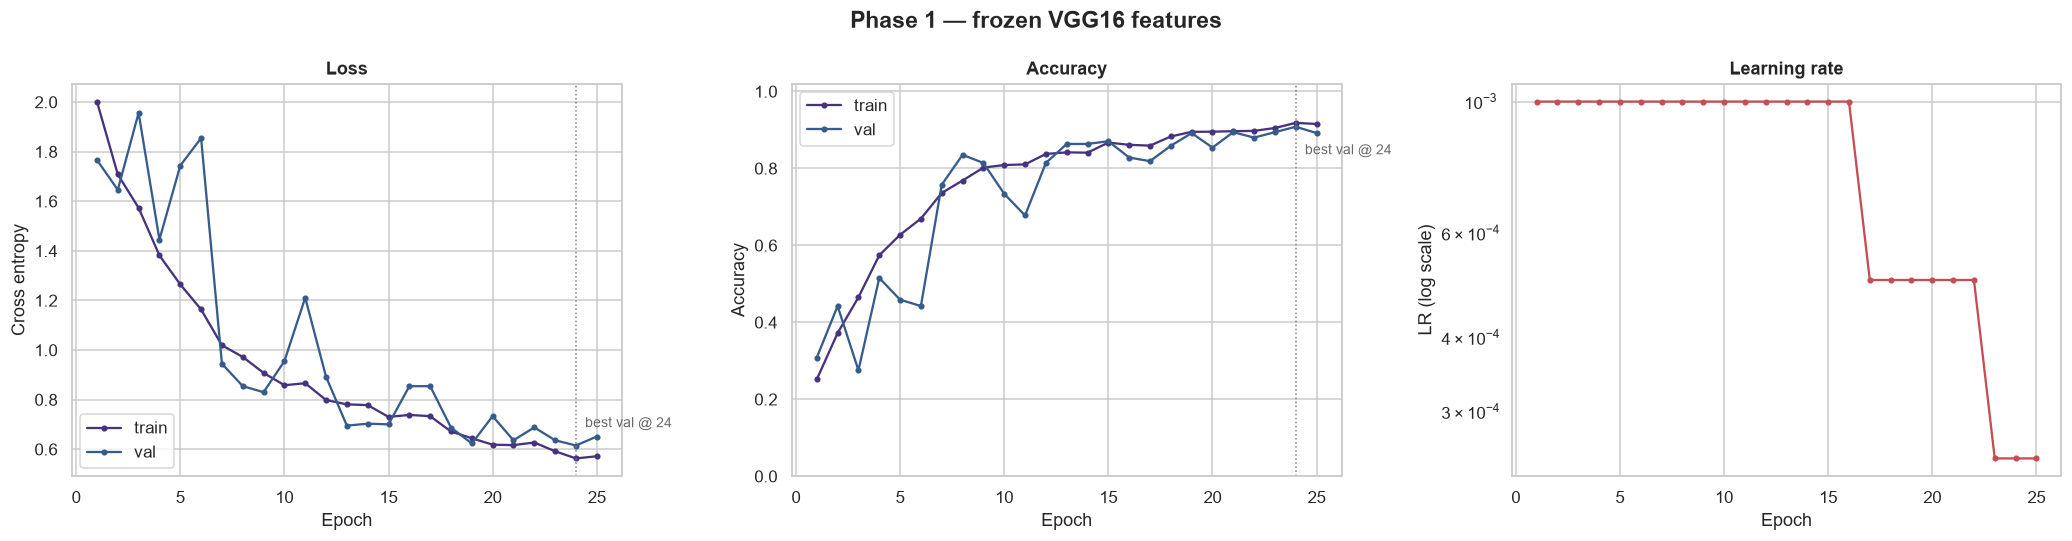

In [14]:
history_1 = fit(model, train_loader, val_loader, EPOCHS_HEAD, LR_HEAD, "phase1")
plot_history(
    history_1,
    title="Phase 1 — frozen VGG16 features",
    fname="05_training_history_phase1.png",
)

## 8. Phase 2 — fine-tune `block5`

Load lại checkpoint tốt nhất của phase 1, sau đó mở các layer `features[24:]` (block5) và train với LR nhỏ `1e-5`.

Nếu val loss tăng mạnh, giảm `LR_FINETUNE` xuống `3e-6` hoặc chỉ mở `features[26:]`.

In [15]:
# Bắt đầu phase 2 từ checkpoint tốt nhất phase 1
best_ckpt = load_checkpoint(BEST_MODEL_PATH)
model.load_state_dict(best_ckpt["model_state_dict"])
print("Loaded best phase-1 checkpoint, val_acc =", best_ckpt["val_accuracy"])

# Mở block5

for param in model.features[24:].parameters():
    param.requires_grad = True

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params after unfreeze: {trainable_params:,}")
print("Các layer block5 đã mở.")

Loaded best phase-1 checkpoint, val_acc = 0.908235294117647
Trainable params after unfreeze: 15,112,778
Các layer block5 đã mở.


[phase2] 01/20 | train loss 0.5373 acc 0.9242 | val loss 0.6002 acc 0.9082 | lr 3.00e-05 | 17.7s
[phase2] 02/20 | train loss 0.5425 acc 0.9233 | val loss 0.6036 acc 0.9082 | lr 3.00e-05 | 17.6s
[phase2] 03/20 | train loss 0.5313 acc 0.9287 | val loss 0.5951 acc 0.9106 | lr 3.00e-05 | 17.4s  *best saved*
[phase2] 04/20 | train loss 0.5288 acc 0.9287 | val loss 0.6053 acc 0.9059 | lr 3.00e-05 | 17.4s
[phase2] 05/20 | train loss 0.5247 acc 0.9304 | val loss 0.6057 acc 0.9059 | lr 3.00e-05 | 17.9s
[phase2] 06/20 | train loss 0.5298 acc 0.9279 | val loss 0.5998 acc 0.9082 | lr 3.00e-05 | 17.5s
[phase2] 07/20 | train loss 0.5295 acc 0.9283 | val loss 0.6048 acc 0.9035 | lr 1.50e-05 | 17.4s
[phase2] 08/20 | train loss 0.5126 acc 0.9363 | val loss 0.6003 acc 0.9059 | lr 1.50e-05 | 18.1s
[phase2] 09/20 | train loss 0.5236 acc 0.9279 | val loss 0.5946 acc 0.9129 | lr 1.50e-05 | 16.7s  *best saved*
[phase2] 10/20 | train loss 0.5159 acc 0.9333 | val loss 0.6012 acc 0.9106 | lr 1.50e-05 | 16.3s
[p

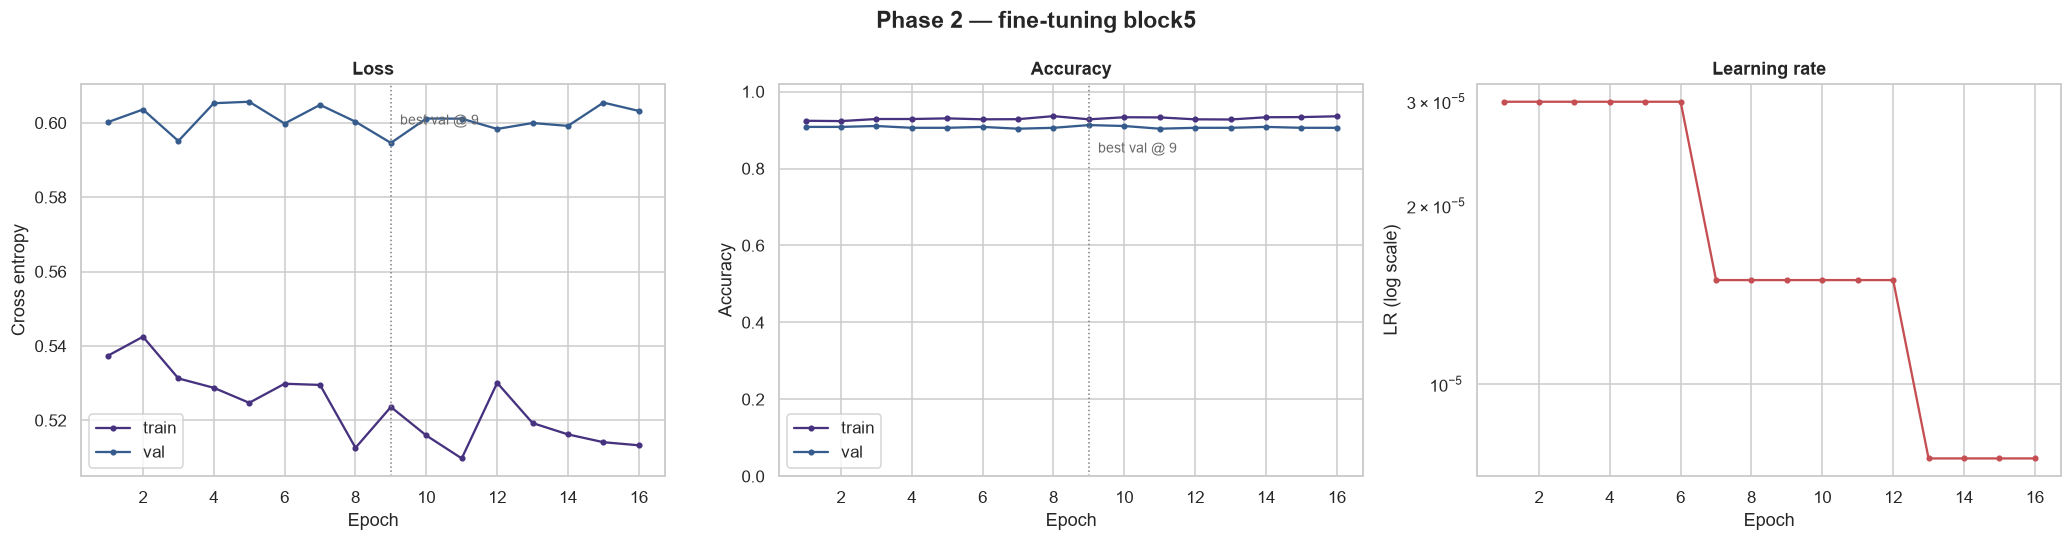

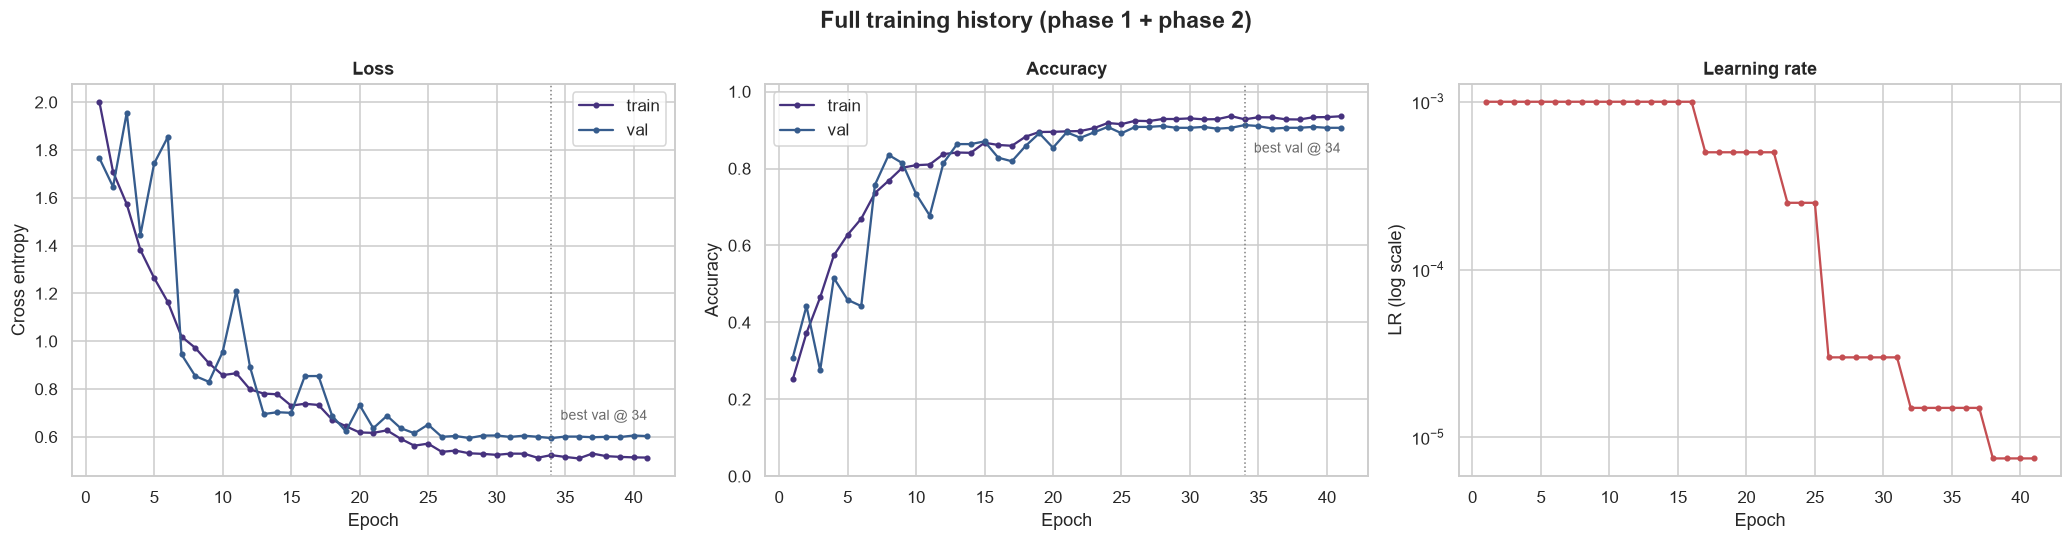

Loaded best checkpoint: val_acc=0.9129, phase=phase2, epoch=9


In [16]:
history_2 = fit(model, train_loader, val_loader, EPOCHS_FINETUNE, LR_FINETUNE, "phase2")
plot_history(
    history_2,
    title="Phase 2 — fine-tuning block5",
    fname="06_training_history_phase2.png",
)

combined_history = {
    key: history_1[key] + history_2[key]
    for key in ["phase", "train_loss", "val_loss", "train_acc", "val_acc", "lr"]
}
plot_history(
    combined_history,
    title="Full training history (phase 1 + phase 2)",
    fname="07_training_history_full.png",
)

# Load checkpoint tốt nhất toàn bộ 2 phase
best_ckpt = load_checkpoint(BEST_MODEL_PATH)
model.load_state_dict(best_ckpt["model_state_dict"])
print(
    f"Loaded best checkpoint: val_acc={best_ckpt['val_accuracy']:.4f}, "
    f"phase={best_ckpt['phase']}, epoch={best_ckpt['epoch']}"
)

## 9. Đánh giá tổng hợp

Load best checkpoint, dự đoán validation và test, tính:
- Accuracy, balanced accuracy, macro F1, top-2 accuracy, log loss, ECE.
- Confusion matrix, precision/recall/F1 từng lớp.

,validation,test (label_book)
accuracy,0.9129,0.9423
balanced_accuracy,0.9098,0.9433
macro_f1,0.9102,0.9428
top2_accuracy,0.9459,0.9808
log_loss,0.3558,0.2542
ECE,0.0338,0.0679


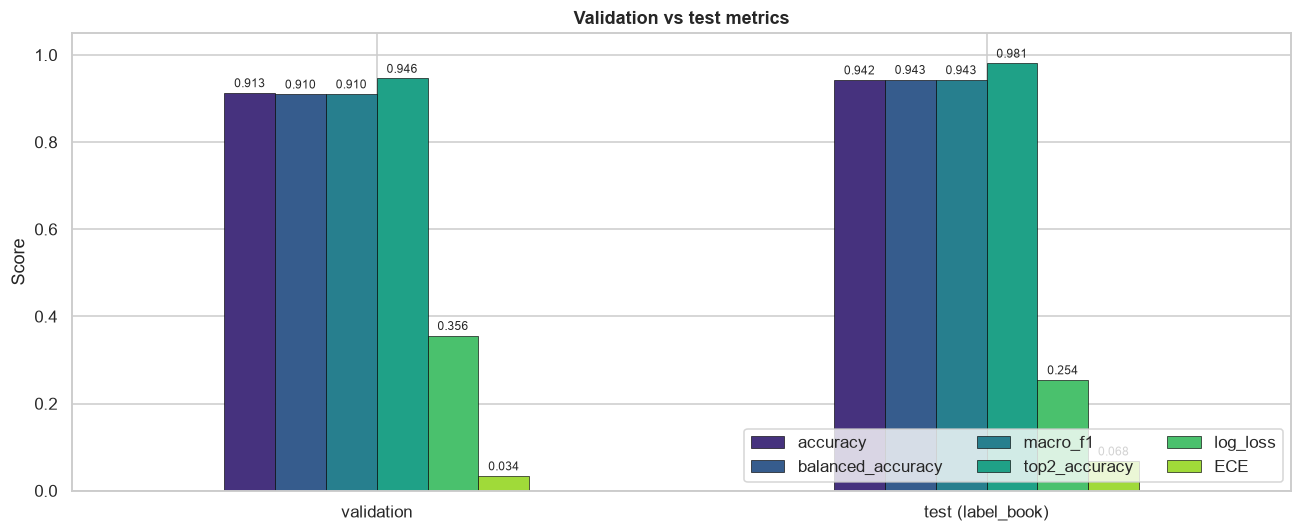

In [17]:
@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    all_probs, all_true = [], []
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        logits = model(images)
        probs = torch.softmax(logits.float(), dim=1).cpu().numpy()
        all_probs.append(probs)
        all_true.append(labels.numpy())
    return np.concatenate(all_probs), np.concatenate(all_true)


val_probs, val_true = predict_loader(model, val_loader)
test_probs, test_true = predict_loader(model, test_loader)
val_pred = val_probs.argmax(axis=1)
test_pred = test_probs.argmax(axis=1)


def expected_calibration_error(y_true, probs, n_bins=10):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    acc = (pred == y_true).astype(np.float32)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() > 0:
            ece += mask.mean() * abs(acc[mask].mean() - conf[mask].mean())
    return float(ece)


def compute_metrics(y_true, probs):
    pred = probs.argmax(axis=1)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro"),
        "top2_accuracy": top_k_accuracy_score(y_true, probs, k=2, labels=np.arange(NUM_CLASSES)),
        "log_loss": log_loss(y_true, probs, labels=np.arange(NUM_CLASSES)),
        "ECE": expected_calibration_error(y_true, probs),
    }


metrics_val = compute_metrics(val_true, val_probs)
metrics_test = compute_metrics(test_true, test_probs)
metrics_table = pd.DataFrame({"validation": metrics_val, "test (label_book)": metrics_test})
metrics_table.to_csv(REPORT_DIR / "metrics_summary.csv")
display(metrics_table.round(4))

fig, ax = plt.subplots(figsize=(12, 5))
metrics_table.T.plot(kind="bar", ax=ax, edgecolor="black", linewidth=0.4)
ax.set_title("Validation vs test metrics")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.legend(loc="lower right", ncol=3)
plt.tight_layout()
plt.savefig(REPORT_DIR / "08_metrics_comparison.png", bbox_inches="tight")
plt.show()

### 9.1. Classification report & confusion matrix

VALIDATION
              precision    recall  f1-score   support

           i     0.9375    0.9000    0.9184        50
          ii     0.8889    0.8889    0.8889        36
         iii     0.8250    0.8462    0.8354        39
          iv     0.9464    0.9815    0.9636        54
           v     0.8750    0.8537    0.8642        41
          vi     0.9750    0.9750    0.9750        40
         vii     0.8810    0.9250    0.9024        40
        viii     0.9070    0.9286    0.9176        42
          ix     0.9348    0.9348    0.9348        46
           x     0.9412    0.8649    0.9014        37

    accuracy                         0.9129       425
   macro avg     0.9112    0.9098    0.9102       425
weighted avg     0.9134    0.9129    0.9128       425

TEST / label_book
              precision    recall  f1-score   support

           i     0.8333    1.0000    0.9091         5
          ii     1.0000    0.8000    0.8889         5
         iii     0.8571    1.0000    0.9231      

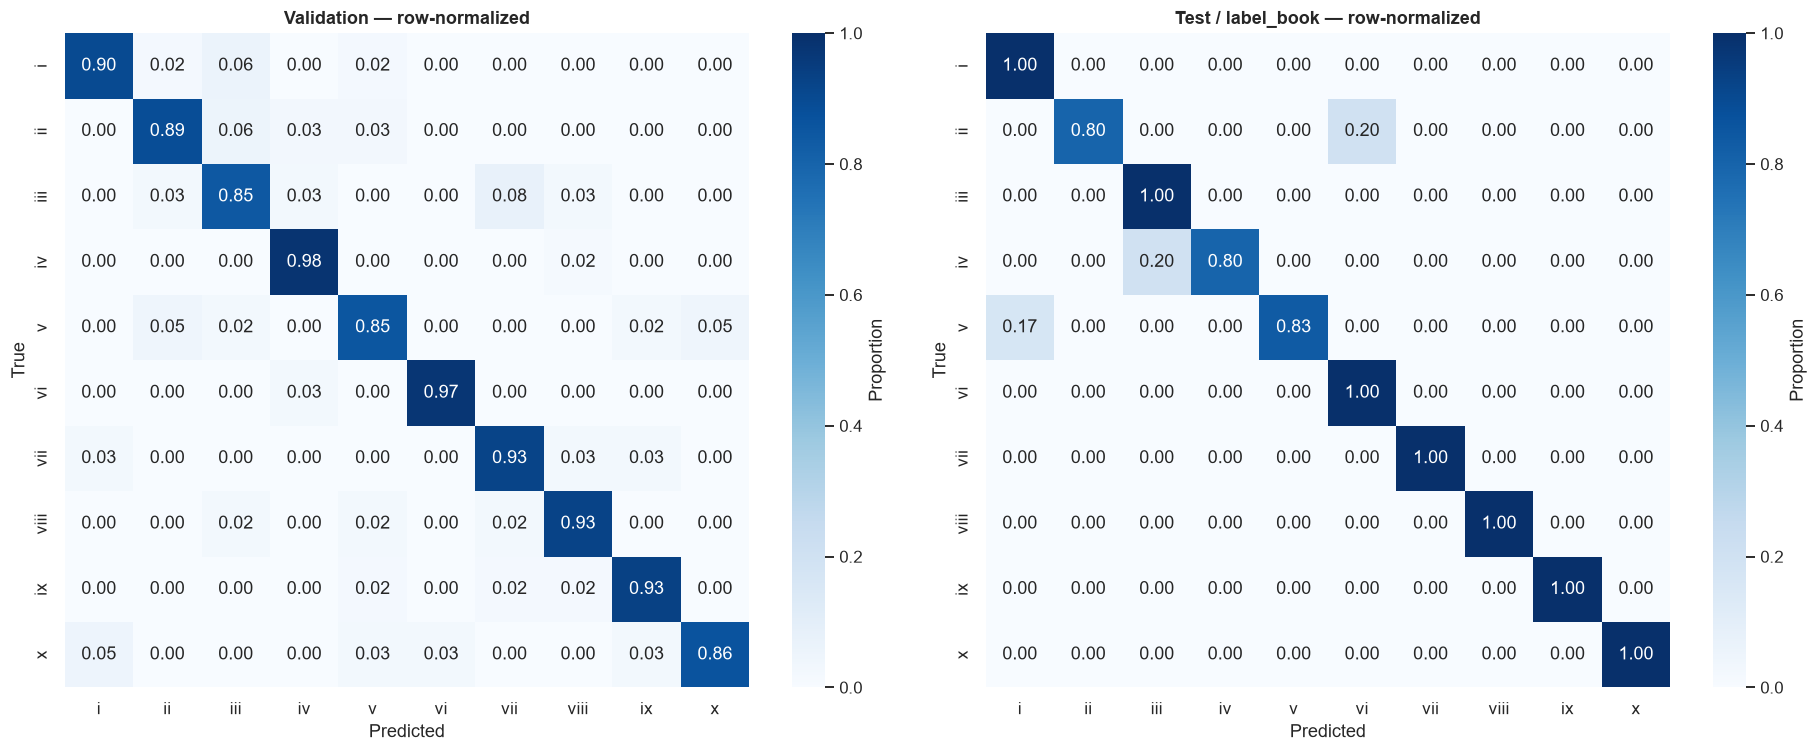

In [18]:
for name, y_true, y_pred in [
    ("VALIDATION", val_true, val_pred),
    ("TEST / label_book", test_true, test_pred),
]:
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(
        y_true, y_pred, labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES, digits=4, zero_division=0,
    ))


def plot_confusion(y_true, y_pred, title, ax, normalize=True):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    if normalize:
        with np.errstate(divide="ignore", invalid="ignore"):
            cm_plot = cm / cm.sum(axis=1, keepdims=True)
        cm_plot = np.nan_to_num(cm_plot)
        fmt = ".2f"
        vmax = 1.0
    else:
        cm_plot = cm
        fmt = "d"
        vmax = cm.max()
    sns.heatmap(
        cm_plot, annot=True, fmt=fmt, cmap="Blues", vmin=0, vmax=vmax,
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        cbar_kws={"label": "Proportion" if normalize else "Count"},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    return cm


fig, axes = plt.subplots(1, 2, figsize=(17, 7))
cm_val = plot_confusion(val_true, val_pred, "Validation — row-normalized", axes[0])
cm_test = plot_confusion(test_true, test_pred, "Test / label_book — row-normalized", axes[1])
plt.tight_layout()
plt.savefig(REPORT_DIR / "09_confusion_matrix.png", bbox_inches="tight")
plt.show()

pd.DataFrame(cm_val, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(REPORT_DIR / "confusion_matrix_val.csv")
pd.DataFrame(cm_test, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(REPORT_DIR / "confusion_matrix_test.csv")

### 9.2. Precision / Recall / F1 theo từng lớp

Validation per-class:


,precision,recall,f1,support
i,0.938,0.900,0.918,50
ii,0.889,0.889,0.889,36
iii,0.825,0.846,0.835,39
iv,0.946,0.981,0.964,54
v,0.875,0.854,0.864,41
vi,0.975,0.975,0.975,40
vii,0.881,0.925,0.902,40
viii,0.907,0.929,0.918,42
ix,0.935,0.935,0.935,46
x,0.941,0.865,0.901,37


Test per-class:


,precision,recall,f1,support
i,0.833,1.000,0.909,5
ii,1.000,0.800,0.889,5
iii,0.857,1.000,0.923,6
iv,1.000,0.800,0.889,5
v,1.000,0.833,0.909,6
vi,0.833,1.000,0.909,5
vii,1.000,1.000,1.000,5
viii,1.000,1.000,1.000,5
ix,1.000,1.000,1.000,5
x,1.000,1.000,1.000,5


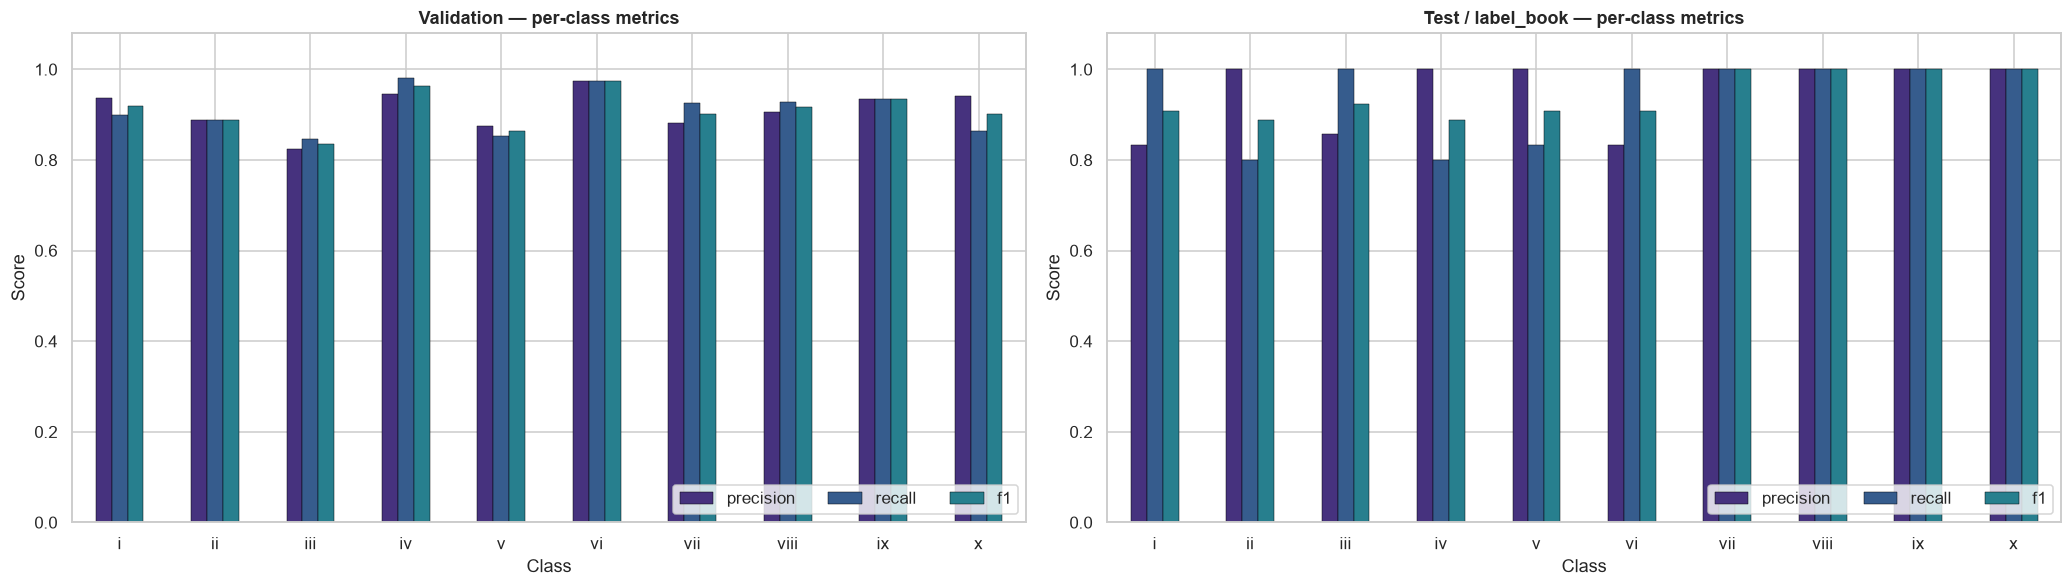

In [19]:
def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(NUM_CLASSES), zero_division=0
    )
    return pd.DataFrame({
        "precision": p, "recall": r, "f1": f, "support": s,
    }, index=CLASS_NAMES)


per_class_val = per_class_table(val_true, val_pred)
per_class_test = per_class_table(test_true, test_pred)
per_class_val.to_csv(REPORT_DIR / "per_class_metrics_val.csv")
per_class_test.to_csv(REPORT_DIR / "per_class_metrics_test.csv")

print("Validation per-class:")
display(per_class_val.round(3))
print("Test per-class:")
display(per_class_test.round(3))

fig, axes = plt.subplots(1, 2, figsize=(19, 5.5))
for ax, table, title in [
    (axes[0], per_class_val, "Validation"),
    (axes[1], per_class_test, "Test / label_book"),
]:
    table[["precision", "recall", "f1"]].plot(kind="bar", ax=ax, edgecolor="black", linewidth=0.3)
    ax.set_title(f"{title} — per-class metrics")
    ax.set_ylim(0, 1.08)
    ax.set_xlabel("Class")
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(loc="lower right", ncol=3)

plt.tight_layout()
plt.savefig(REPORT_DIR / "10_per_class_metrics.png", bbox_inches="tight")
plt.show()

### 9.3. Confidence & calibration

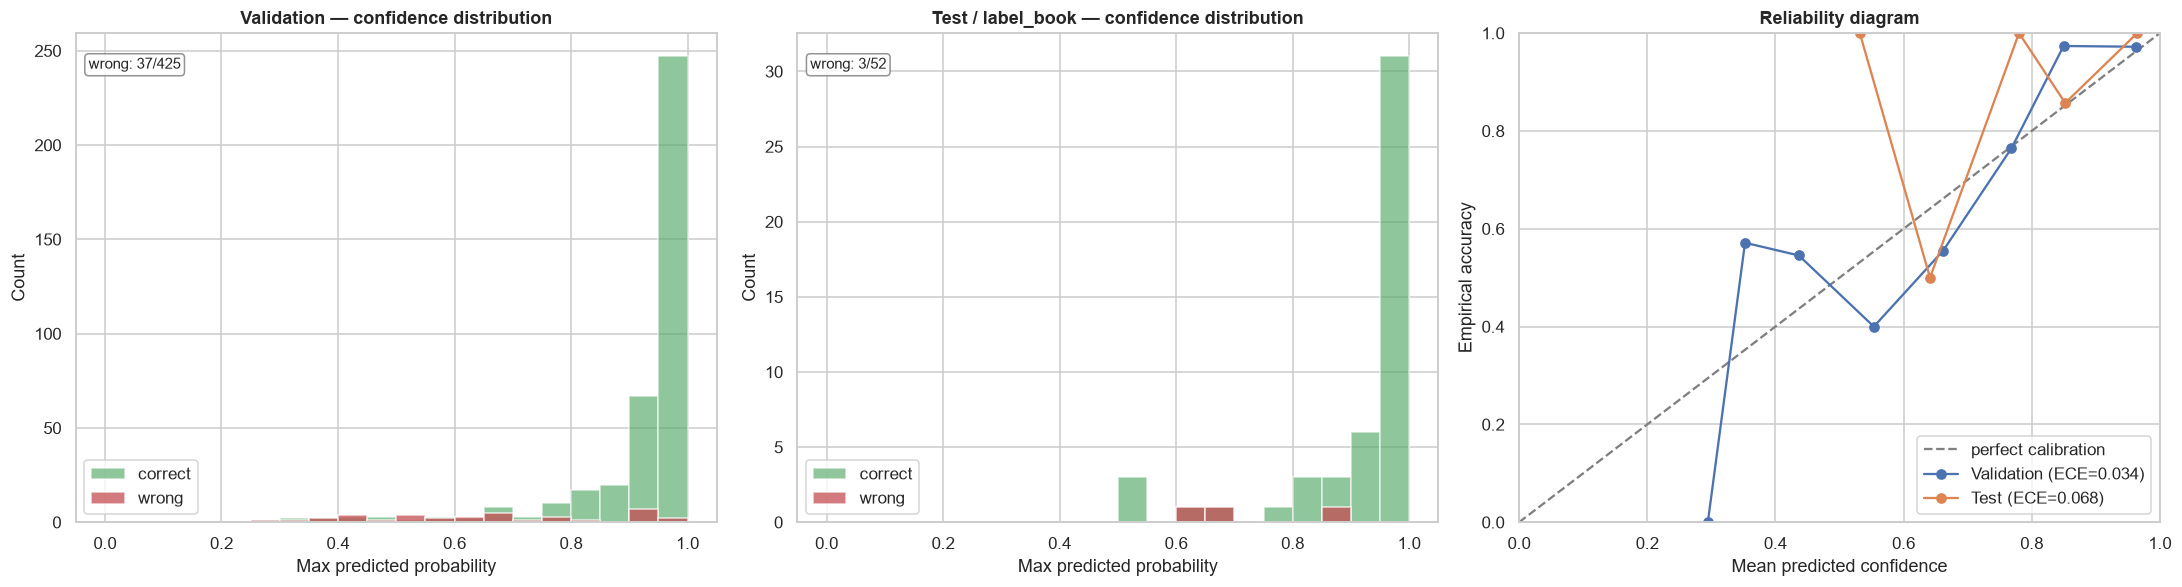

In [20]:
def reliability_curve(y_true, probs, n_bins=10):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    correct = (pred == y_true).astype(np.float32)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    centers, accs, counts = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() > 0:
            centers.append(conf[mask].mean())
            accs.append(correct[mask].mean())
            counts.append(int(mask.sum()))
    return np.array(centers), np.array(accs), np.array(counts)


fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

for ax, (name, y_true, probs) in zip(
    axes[:2],
    [("Validation", val_true, val_probs), ("Test / label_book", test_true, test_probs)],
):
    conf = probs.max(axis=1)
    correct = probs.argmax(axis=1) == y_true
    bins = np.linspace(0.0, 1.0, 21)
    ax.hist(conf[correct], bins=bins, alpha=0.65, label="correct", color="#55A868")
    ax.hist(conf[~correct], bins=bins, alpha=0.75, label="wrong", color="#C44E52")
    ax.set_title(f"{name} — confidence distribution")
    ax.set_xlabel("Max predicted probability")
    ax.set_ylabel("Count")
    ax.legend()
    ax.text(
        0.02, 0.95, f"wrong: {int((~correct).sum())}/{len(correct)}",
        transform=ax.transAxes, va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="gray", alpha=0.85),
    )

ax = axes[2]
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="perfect calibration")
for name, y_true, probs, color in [
    ("Validation", val_true, val_probs, "#4C72B0"),
    ("Test", test_true, test_probs, "#DD8452"),
]:
    centers, accs, _ = reliability_curve(y_true, probs, n_bins=10)
    ax.plot(
        centers, accs, marker="o",
        label=f"{name} (ECE={expected_calibration_error(y_true, probs):.3f})",
        color=color,
    )
ax.set_title("Reliability diagram")
ax.set_xlabel("Mean predicted confidence")
ax.set_ylabel("Empirical accuracy")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig(REPORT_DIR / "11_confidence_calibration.png", bbox_inches="tight")
plt.show()

### 9.4. Các cặp lớp bị nhầm nhiều nhất

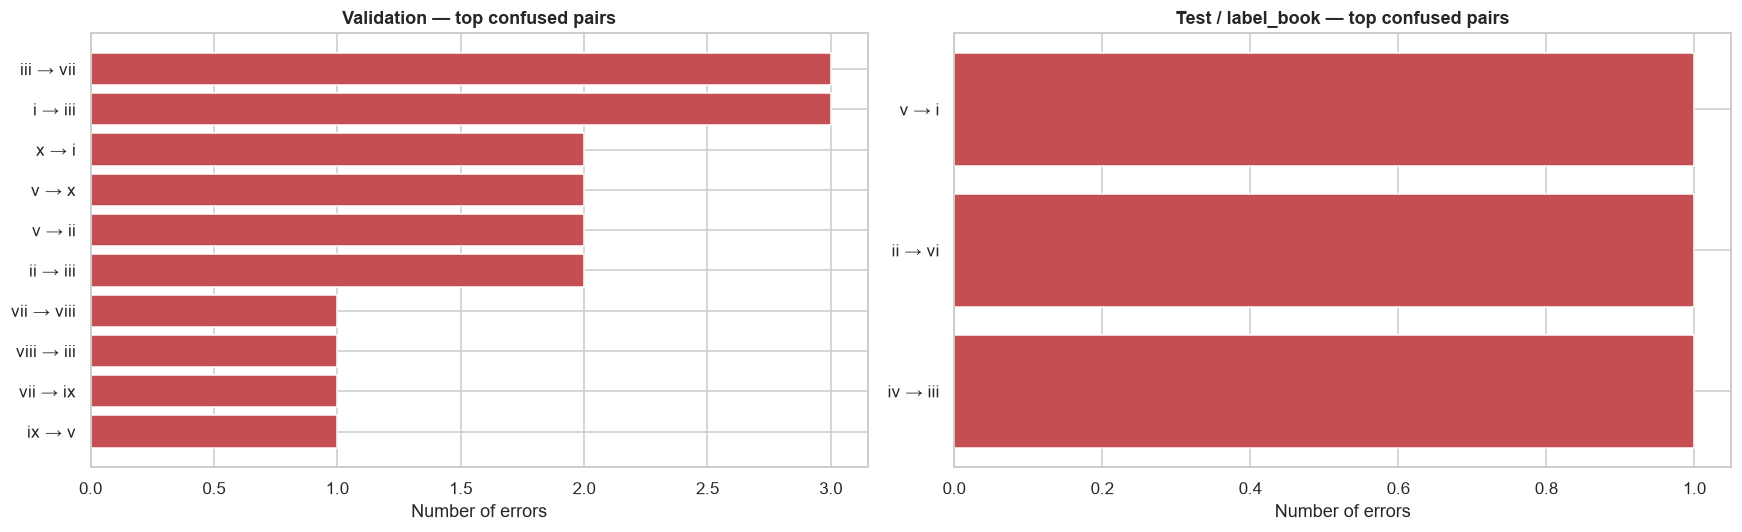

,true,predicted,count
0,iii,vii,3
1,i,iii,3
2,x,i,2
3,v,x,2
4,v,ii,2
5,ii,iii,2
6,vii,viii,1
7,viii,iii,1
8,vii,ix,1
9,ix,v,1


,true,predicted,count
0,v,i,1
1,ii,vi,1
2,iv,iii,1


In [21]:
def top_confused_pairs(y_true, y_pred, top_n=10):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    off_diag = cm.copy()
    np.fill_diagonal(off_diag, 0)
    flat = np.argsort(off_diag.ravel())[::-1][:top_n]
    rows = []
    for idx in flat:
        i, j = np.unravel_index(idx, off_diag.shape)
        if off_diag[i, j] > 0:
            rows.append({
                "true": CLASS_NAMES[i],
                "predicted": CLASS_NAMES[j],
                "count": int(off_diag[i, j]),
            })
    return pd.DataFrame(rows)


pairs_val = top_confused_pairs(val_true, val_pred)
pairs_test = top_confused_pairs(test_true, test_pred)
pairs_val.to_csv(REPORT_DIR / "top_confusions_val.csv", index=False)
pairs_test.to_csv(REPORT_DIR / "top_confusions_test.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, pairs, title in [
    (axes[0], pairs_val, "Validation"),
    (axes[1], pairs_test, "Test / label_book"),
]:
    if len(pairs) == 0:
        ax.axis("off")
        ax.set_title(f"{title} — no confusions")
        continue
    labels = [f"{r.true} → {r.predicted}" for r in pairs.itertuples()]
    ax.barh(labels[::-1], pairs["count"].values[::-1], color="#C44E52")
    ax.set_title(f"{title} — top confused pairs")
    ax.set_xlabel("Number of errors")
plt.tight_layout()
plt.savefig(REPORT_DIR / "12_top_confused_pairs.png", bbox_inches="tight")
plt.show()

display(pairs_val)
display(pairs_test)

## 10. Xem ảnh bị dự đoán sai

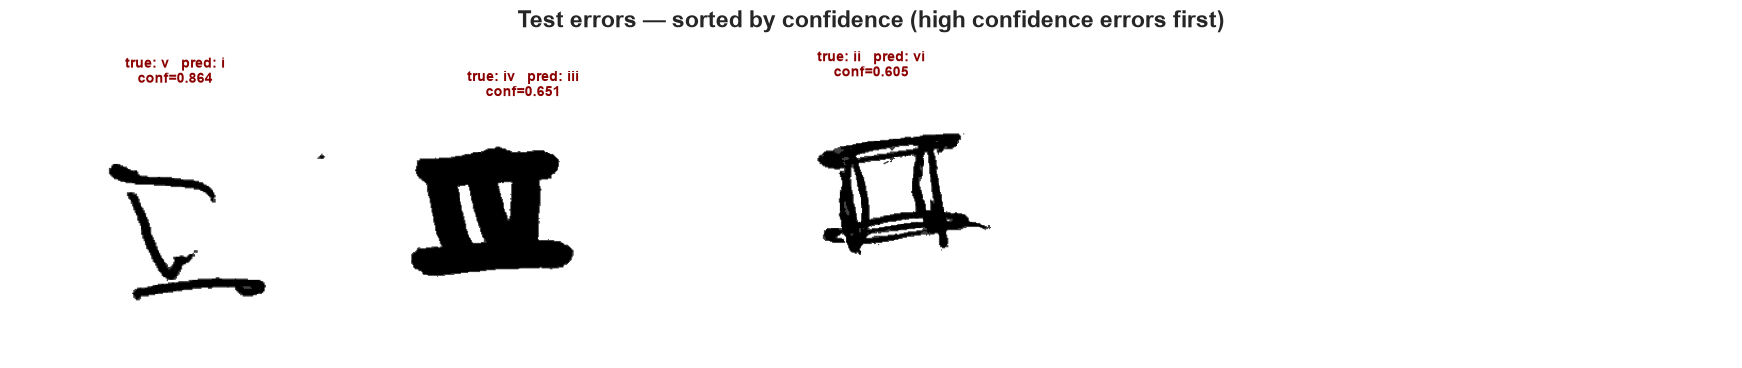

,path,true,predicted,confidence
0,C:\Users\Administrator\Downloads\deeplearninga...,v,i,0.864064
1,C:\Users\Administrator\Downloads\deeplearninga...,iv,iii,0.651192
2,C:\Users\Administrator\Downloads\deeplearninga...,ii,vi,0.605220


In [22]:
def show_predictions(frame, probs, title, n=20, only_errors=True, fname=None):
    true = frame["label"].values
    pred = probs.argmax(axis=1)
    conf = probs.max(axis=1)
    indices = np.where(pred != true)[0] if only_errors else np.arange(len(frame))
    if len(indices) == 0:
        print("Không có ảnh nào để hiển thị.")
        return
    indices = indices[np.argsort(-conf[indices])][:n]

    n_cols = 5
    n_rows = int(np.ceil(len(indices) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 3.4 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, idx in zip(axes, indices):
        with Image.open(frame.iloc[idx]["path"]) as im:
            ax.imshow(im.convert("L"), cmap="gray")
        ax.axis("off")
        color = "darkred" if pred[idx] != true[idx] else "darkgreen"
        ax.set_title(
            f"true: {CLASS_NAMES[true[idx]]}   pred: {CLASS_NAMES[pred[idx]]}\n"
            f"conf={conf[idx]:.3f}",
            fontsize=9, color=color,
        )
    for ax in axes[len(indices):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=15, fontweight="bold")
    plt.tight_layout()
    if fname:
        plt.savefig(REPORT_DIR / fname, bbox_inches="tight")
    plt.show()

    return pd.DataFrame({
        "path": frame.iloc[indices]["path"].values,
        "true": [CLASS_NAMES[i] for i in true[indices]],
        "predicted": [CLASS_NAMES[i] for i in pred[indices]],
        "confidence": conf[indices],
    })


errors_test = show_predictions(
    test_df, test_probs,
    "Test errors — sorted by confidence (high confidence errors first)",
    n=20, only_errors=True, fname="13_test_errors.png",
)
if errors_test is not None:
    display(errors_test)

## 11. Lưu toàn bộ dự đoán

In [23]:
def prediction_table(frame, probs):
    pred = probs.argmax(axis=1)
    out = pd.DataFrame({
        "path": frame["path"].values,
        "true": [CLASS_NAMES[i] for i in frame["label"].values],
        "predicted": [CLASS_NAMES[i] for i in pred],
        "confidence": probs.max(axis=1),
        "correct": pred == frame["label"].values,
    })
    for i, class_name in enumerate(CLASS_NAMES):
        out[f"p_{class_name}"] = probs[:, i]
    return out.sort_values(["correct", "confidence"], ascending=[True, False])


pred_val_df = prediction_table(val_df, val_probs)
pred_test_df = prediction_table(test_df, test_probs)
pred_val_df.to_csv(REPORT_DIR / "predictions_val.csv", index=False)
pred_test_df.to_csv(REPORT_DIR / "predictions_test.csv", index=False)

print("Số lỗi validation:", int((~pred_val_df["correct"]).sum()), "/", len(pred_val_df))
print("Số lỗi test      :", int((~pred_test_df["correct"]).sum()), "/", len(pred_test_df))
display(pred_test_df.head(15))

Số lỗi validation: 37 / 425
Số lỗi test      : 3 / 52


,path,true,predicted,confidence,correct,p_i,p_ii,p_iii,p_iv,p_v,p_vi,p_vii,p_viii,p_ix,p_x
23,C:\Users\Administrator\Downloads\deeplearninga...,v,i,0.864064,False,0.864064,0.016606,0.007036,0.002389,0.014216,0.025966,0.006201,0.007734,0.008318,0.047470
18,C:\Users\Administrator\Downloads\deeplearninga...,iv,iii,0.651192,False,0.010549,0.011986,0.651192,0.223348,0.005758,0.029211,0.004274,0.034136,0.022054,0.007492
7,C:\Users\Administrator\Downloads\deeplearninga...,ii,vi,0.605220,False,0.014993,0.115944,0.055253,0.009968,0.046883,0.605220,0.107472,0.014310,0.015032,0.014926
48,C:\Users\Administrator\Downloads\deeplearninga...,x,x,0.988176,True,0.000369,0.001768,0.000558,0.001149,0.002606,0.001162,0.000471,0.001420,0.002321,0.988176
37,C:\Users\Administrator\Downloads\deeplearninga...,viii,viii,0.987504,True,0.000943,0.002068,0.000486,0.002573,0.001260,0.000931,0.000319,0.987504,0.002074,0.001842
9,C:\Users\Administrator\Downloads\deeplearninga...,ii,ii,0.986852,True,0.004146,0.986852,0.002624,0.000246,0.001319,0.001103,0.001022,0.000755,0.001224,0.000709
11,C:\Users\Administrator\Downloads\deeplearninga...,iii,iii,0.986579,True,0.000823,0.002097,0.986579,0.001343,0.000480,0.000602,0.000341,0.006601,0.000169,0.000965
39,C:\Users\Administrator\Downloads\deeplearninga...,viii,viii,0.985993,True,0.000650,0.001543,0.000282,0.003465,0.000614,0.001082,0.000083,0.985993,0.004862,0.001427
35,C:\Users\Administrator\Downloads\deeplearninga...,vii,vii,0.984847,True,0.000624,0.001016,0.001266,0.000255,0.001442,0.005723,0.984847,0.003709,0.000482,0.000636
34,C:\Users\Administrator\Downloads\deeplearninga...,vii,vii,0.984766,True,0.000774,0.001982,0.001589,0.000153,0.001417,0.002786,0.984766,0.005142,0.000512,0.000879


## 12. Grad-CAM — model đang nhìn vào đâu?

Grad-CAM tô đỏ vùng ảnh ảnh hưởng mạnh tới dự đoán. Nếu vùng đỏ nằm ngoài nét chữ, model có thể đang học shortcut từ nền/viền.

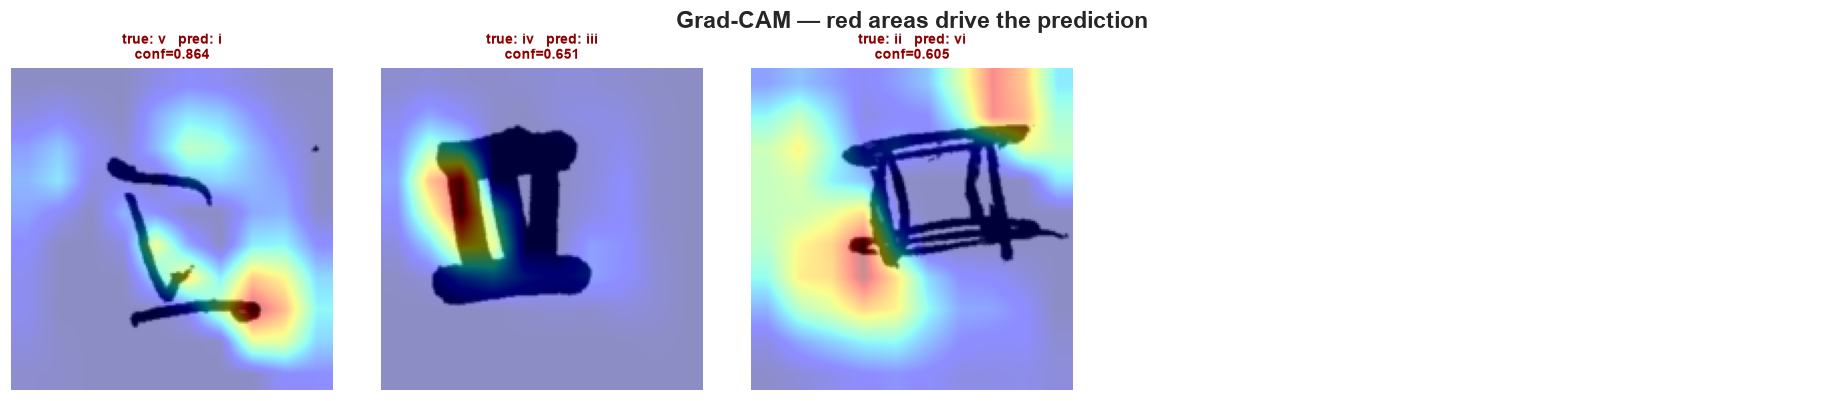

In [24]:
def get_last_conv_layer(model):
    for layer in reversed(model.features):
        if isinstance(layer, nn.Conv2d):
            return layer
    raise ValueError("Không tìm thấy Conv2d trong model.features")


def make_gradcam_heatmap(image_tensor, model, class_idx=None):
    model.eval()
    activations = {}

    def forward_hook(module, inputs, output):
        activations["value"] = output

    target_layer = get_last_conv_layer(model)
    handle = target_layer.register_forward_hook(forward_hook)
    try:
        x = image_tensor.clone().detach().unsqueeze(0).to(DEVICE).requires_grad_(True)
        logits = model(x)
        if class_idx is None:
            class_idx = int(logits.argmax(dim=1).item())
        score = logits[0, class_idx]
        grads = torch.autograd.grad(score, activations["value"])[0]
    finally:
        handle.remove()

    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = (weights * activations["value"]).sum(dim=1).clamp(min=0)
    cam = F.interpolate(
        cam.unsqueeze(1), size=(IMG_SIZE[1], IMG_SIZE[0]),
        mode="bilinear", align_corners=False,
    )[0, 0]
    cam = cam.detach().cpu()
    cam = cam / (cam.max() + 1e-8)
    probs = torch.softmax(logits, dim=1)[0].detach().cpu().numpy()
    return cam.numpy(), class_idx, probs


def show_gradcam(model, frame, probs, n=10, only_errors=True, fname="14_gradcam.png"):
    true = frame["label"].values
    pred = probs.argmax(axis=1)
    conf = probs.max(axis=1)
    indices = np.where(pred != true)[0] if only_errors else np.arange(len(frame))
    if len(indices) == 0:
        indices = np.argsort(-conf)[:n]
    indices = indices[np.argsort(-conf[indices])][:n]

    n_cols = 5
    n_rows = int(np.ceil(len(indices) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.4 * n_cols, 3.7 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, idx in zip(axes, indices):
        with Image.open(frame.iloc[idx]["path"]) as im:
            image = im.convert("L")
        tensor = val_transform(image)
        heatmap, class_idx, probabilities = make_gradcam_heatmap(tensor, model)
        display_image = denormalize(tensor).permute(1, 2, 0).numpy()

        ax.imshow(display_image)
        ax.imshow(heatmap, cmap="jet", alpha=0.45)
        ax.axis("off")
        ax.set_title(
            f"true: {CLASS_NAMES[true[idx]]}   pred: {CLASS_NAMES[class_idx]}\n"
            f"conf={probabilities[class_idx]:.3f}",
            fontsize=9,
            color="darkred" if class_idx != true[idx] else "darkgreen",
        )

    for ax in axes[len(indices):]:
        ax.axis("off")
    fig.suptitle("Grad-CAM — red areas drive the prediction", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(REPORT_DIR / fname, bbox_inches="tight")
    plt.show()


show_gradcam(model, test_df, test_probs, n=10, only_errors=True)

## 13. Lưu model, lịch sử train và metadata

- `vgg16_roman_best.pt`: checkpoint tốt nhất theo validation.
- `vgg16_roman_final.pt`: model cuối + config + class names để load lại.
- `training_history_full.csv`, `model_metadata.json`.

In [25]:
final_checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "image_size": list(IMG_SIZE),
    "mean": list(MEAN),
    "std": list(STD),
    "test_metrics": {k: float(v) for k, v in metrics_test.items()},
    "config": {
        "model": "vgg16",
        "num_classes": NUM_CLASSES,
        "batch_size": BATCH_SIZE,
        "img_size": list(IMG_SIZE),
    },
}
torch.save(final_checkpoint, FINAL_MODEL_PATH)

history_df = pd.DataFrame(combined_history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
history_df.to_csv(REPORT_DIR / "training_history_full.csv", index=False)

metadata = {
    "model": "VGG16-PyTorch",
    "class_names": CLASS_NAMES,
    "image_size": list(IMG_SIZE),
    "num_classes": NUM_CLASSES,
    "normalization": {"mean": list(MEAN), "std": list(STD)},
    "best_val_accuracy": float(max(combined_history["val_acc"])),
    "test_accuracy": float(metrics_test["accuracy"]),
    "test_balanced_accuracy": float(metrics_test["balanced_accuracy"]),
    "test_macro_f1": float(metrics_test["macro_f1"]),
    "test_ece": float(metrics_test["ECE"]),
    "train_size": int(len(train_df)),
    "val_size": int(len(val_df)),
    "test_size": int(len(test_df)),
    "augmentation": "rotation/zoom/translation/contrast/brightness only; NO flips",
}
with open(MODEL_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print("Đã lưu model :", FINAL_MODEL_PATH)
print("Đã lưu report:", REPORT_DIR)
print("\nCác file trong reports/:")
for path in sorted(REPORT_DIR.glob("*")):
    print("  -", path.name)

Đã lưu model : c:\Users\Administrator\Downloads\deeplearningai-data-centric-competition-main\deeplearningai-data-centric-competition-main\models\vgg16_roman_final.pt
Đã lưu report: c:\Users\Administrator\Downloads\deeplearningai-data-centric-competition-main\deeplearningai-data-centric-competition-main\reports

Các file trong reports/:
  - 01_class_distribution.png
  - 02_image_geometry_brightness.png
  - 03_sample_gallery.png
  - 04_augmentation_examples.png
  - 05_training_history_phase1.png
  - 06_training_history_phase2.png
  - 07_training_history_full.png
  - 08_metrics_comparison.png
  - 09_confusion_matrix.png
  - 10_per_class_metrics.png
  - 11_confidence_calibration.png
  - 12_top_confused_pairs.png
  - 13_test_errors.png
  - 14_gradcam.png
  - confusion_matrix_test.csv
  - confusion_matrix_val.csv
  - metrics_summary.csv
  - per_class_metrics_test.csv
  - per_class_metrics_val.csv
  - predictions_test.csv
  - predictions_val.csv
  - top_confusions_test.csv
  - top_confusions_

## 14. Dự đoán một ảnh mới

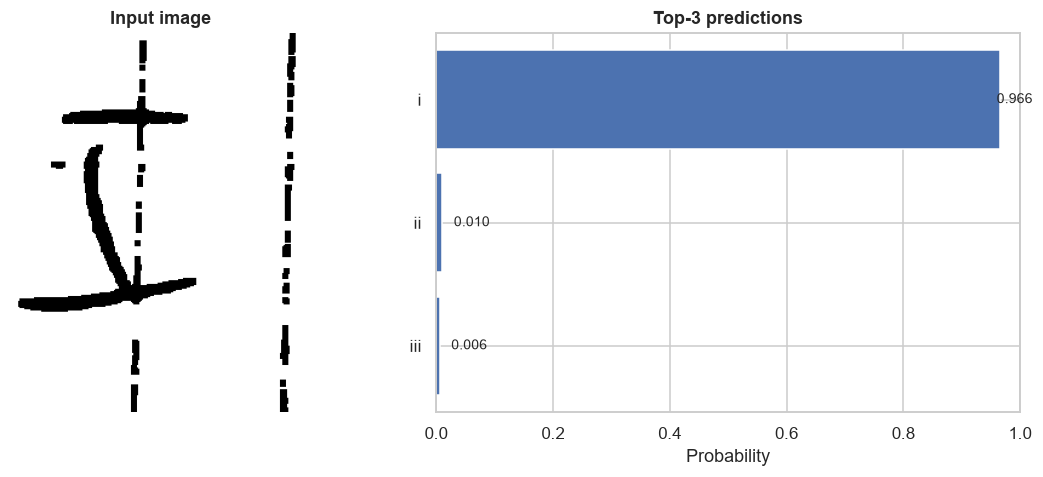

Dự đoán: i  |  confidence = 0.9655


In [26]:
@torch.inference_mode()
def predict_single_image(image_path, top_k=3):
    model.eval()
    with Image.open(image_path) as im:
        image = im.convert("L")
        tensor = val_transform(image).unsqueeze(0).to(DEVICE)
    probs = torch.softmax(model(tensor), dim=1)[0].cpu().numpy()
    order = np.argsort(probs)[::-1][:top_k]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    with Image.open(image_path) as im:
        axes[0].imshow(im.convert("L"), cmap="gray")
    axes[0].axis("off")
    axes[0].set_title("Input image")

    labels = [CLASS_NAMES[i] for i in order][::-1]
    values = [float(probs[i]) for i in order][::-1]
    bars = axes[1].barh(labels, values, color="#4C72B0")
    axes[1].set_xlim(0, 1)
    axes[1].set_xlabel("Probability")
    axes[1].set_title(f"Top-{top_k} predictions")
    for bar, value in zip(bars, values):
        axes[1].text(
            min(value + 0.02, 0.96), bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}", va="center", fontsize=9,
        )
    plt.tight_layout()
    plt.show()

    best = CLASS_NAMES[order[0]]
    print(f"Dự đoán: {best}  |  confidence = {probs[order[0]]:.4f}")
    return best, probs


example_image = test_df.iloc[0]["path"]
_ = predict_single_image(example_image)

## 15. Test đánh giá model đã lưu (chạy độc lập)

Section này **load `models/vgg16_roman_final.pt` từ đĩa** và đánh giá trên test set, mặc định `label_book/`. Có thể chạy lại sau khi train mà không cần train lại.

- Đổi `TEST_EVAL_DIR` nếu muốn folder khác.
- Folder test phải có cấu trúc `i/`, `ii/`, `iii/`, …
- Kết quả lưu trong `reports/test_eval/`.

**Cách dùng:** chạy cell cấu hình mục 1, sau đó chạy lần lượt 3 cell bên dưới.

In [27]:
# =============================================================================
# TEST ĐÁNH GIÁ ĐỘC LẬP — load checkpoint PyTorch và đánh giá
# =============================================================================
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_fscore_support,
    top_k_accuracy_score,
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms

BASE_DIR = globals().get("BASE_DIR", Path.cwd())
CLASS_NAMES = globals().get("CLASS_NAMES", ["i", "ii", "iii", "iv", "v", "vi", "vii", "viii", "ix", "x"])
IMG_SIZE = globals().get("IMG_SIZE", (128, 128))
BATCH_SIZE = globals().get("BATCH_SIZE", 32)
MODEL_DIR = globals().get("MODEL_DIR", BASE_DIR / "models")
REPORT_DIR = globals().get("REPORT_DIR", BASE_DIR / "reports")
LABEL_BOOK_DIR = globals().get("LABEL_BOOK_DIR", BASE_DIR / "label_book")
DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

TEST_EVAL_DIR = LABEL_BOOK_DIR
EVAL_BATCH_SIZE = BATCH_SIZE
EVAL_REPORT_DIR = REPORT_DIR / "test_eval"
EVAL_REPORT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILE = MODEL_DIR / "vgg16_roman_final.pt"
META_FILE = MODEL_DIR / "model_metadata.json"

if not MODEL_FILE.exists():
    raise FileNotFoundError(
        f"Chưa có model: {MODEL_FILE}\n"
        "Hãy chạy phần train + lưu model (mục 13) trước."
    )


def load_torch_checkpoint(path, map_location=DEVICE):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


checkpoint = load_torch_checkpoint(MODEL_FILE)
eval_class_names = checkpoint.get("class_names", CLASS_NAMES)
eval_img_size = tuple(checkpoint.get("image_size", IMG_SIZE))
eval_mean = tuple(checkpoint.get("mean", (0.485, 0.456, 0.406)))
eval_std = tuple(checkpoint.get("std", (0.229, 0.224, 0.225)))
num_eval_classes = len(eval_class_names)

print("Model     :", MODEL_FILE)
print("Test dir  :", TEST_EVAL_DIR)
print("Image size:", eval_img_size)
print("Classes   :", eval_class_names)


class VGG16RomanEval(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        backbone = torchvision.models.vgg16(weights=None)
        self.features = backbone.features
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.50),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.30),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


eval_model = VGG16RomanEval(num_eval_classes).to(DEVICE)
eval_model.load_state_dict(checkpoint["model_state_dict"])
eval_model.eval()

eval_transform = transforms.Compose([
    transforms.Resize((eval_img_size[1], eval_img_size[0])),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=eval_mean, std=eval_std),
])

EVAL_IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}


def scan_eval_folder(folder, class_names):
    rows, bad = [], []
    if not folder.is_dir():
        raise FileNotFoundError(f"Không tìm thấy test folder: {folder}")
    for label, class_name in enumerate(class_names):
        class_dir = folder / class_name
        if not class_dir.is_dir():
            continue
        for path in sorted(class_dir.rglob("*")):
            if not path.is_file() or path.suffix.lower() not in EVAL_IMG_EXTS:
                continue
            try:
                with Image.open(path) as im:
                    im.verify()
                with Image.open(path) as im:
                    width, height = im.size
                rows.append({
                    "path": str(path.resolve()),
                    "label": label,
                    "class_name": class_name,
                    "width": width,
                    "height": height,
                })
            except Exception as exc:
                bad.append((str(path), str(exc)))
    return pd.DataFrame(rows), bad


eval_df, bad_eval = scan_eval_folder(TEST_EVAL_DIR, eval_class_names)
if len(eval_df) == 0:
    raise RuntimeError(f"Không tìm thấy ảnh hợp lệ trong {TEST_EVAL_DIR}")

missing_classes = [c for c in eval_class_names if not (TEST_EVAL_DIR / c).is_dir()]
if missing_classes:
    print("CẢNH BÁO — thiếu folder lớp:", missing_classes)

eval_counts = eval_df.groupby("class_name").size().reindex(eval_class_names, fill_value=0)
print("\nSố ảnh test theo lớp:")
display(eval_counts.to_frame("count").T)
print("Tổng số ảnh test:", len(eval_df))
print("Ảnh hỏng bị bỏ   :", len(bad_eval))


class EvalDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame["path"].tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert("L")
            image = self.transform(image)
        return image, torch.tensor(self.labels[index], dtype=torch.long)


eval_loader = DataLoader(
    EvalDataset(eval_df, eval_transform),
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

eval_probs_list, eval_true_list = [], []
with torch.inference_mode():
    for images, labels in eval_loader:
        images = images.to(DEVICE, non_blocking=True)
        logits = eval_model(images)
        eval_probs_list.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
        eval_true_list.append(labels.numpy())

eval_probs = np.concatenate(eval_probs_list)
eval_true = np.concatenate(eval_true_list)
eval_pred = eval_probs.argmax(axis=1)
eval_conf = eval_probs.max(axis=1)
eval_correct = eval_pred == eval_true

print("\nĐã dự đoán xong.")
print(f"Số đúng: {eval_correct.sum()}/{len(eval_correct)}")

Model     : c:\Users\Administrator\Downloads\deeplearningai-data-centric-competition-main\deeplearningai-data-centric-competition-main\models\vgg16_roman_final.pt
Test dir  : c:\Users\Administrator\Downloads\deeplearningai-data-centric-competition-main\deeplearningai-data-centric-competition-main\label_book
Image size: (160, 160)
Classes   : ['i', 'ii', 'iii', 'iv', 'v', 'vi', 'vii', 'viii', 'ix', 'x']

Số ảnh test theo lớp:


class_name,i,ii,iii,iv,v,vi,vii,viii,ix,x
count,5,5,6,5,6,5,5,5,5,5


Tổng số ảnh test: 52
Ảnh hỏng bị bỏ   : 0

Đã dự đoán xong.
Số đúng: 49/52


KẾT QUẢ TEST ĐÁNH GIÁ


,value
accuracy,0.9423
balanced_accuracy,0.9433
macro_f1,0.9428
weighted_f1,0.9418
top2_accuracy,0.9808
log_loss,0.2542
ECE,0.0679
num_test_images,52.0000
num_errors,3.0000



Classification report:
              precision    recall  f1-score   support

           i     0.8333    1.0000    0.9091         5
          ii     1.0000    0.8000    0.8889         5
         iii     0.8571    1.0000    0.9231         6
          iv     1.0000    0.8000    0.8889         5
           v     1.0000    0.8333    0.9091         6
          vi     0.8333    1.0000    0.9091         5
         vii     1.0000    1.0000    1.0000         5
        viii     1.0000    1.0000    1.0000         5
          ix     1.0000    1.0000    1.0000         5
           x     1.0000    1.0000    1.0000         5

    accuracy                         0.9423        52
   macro avg     0.9524    0.9433    0.9428        52
weighted avg     0.9515    0.9423    0.9418        52


Per-class metrics:


,precision,recall,f1,support
i,0.833,1.000,0.909,5
ii,1.000,0.800,0.889,5
iii,0.857,1.000,0.923,6
iv,1.000,0.800,0.889,5
v,1.000,0.833,0.909,6
vi,0.833,1.000,0.909,5
vii,1.000,1.000,1.000,5
viii,1.000,1.000,1.000,5
ix,1.000,1.000,1.000,5
x,1.000,1.000,1.000,5


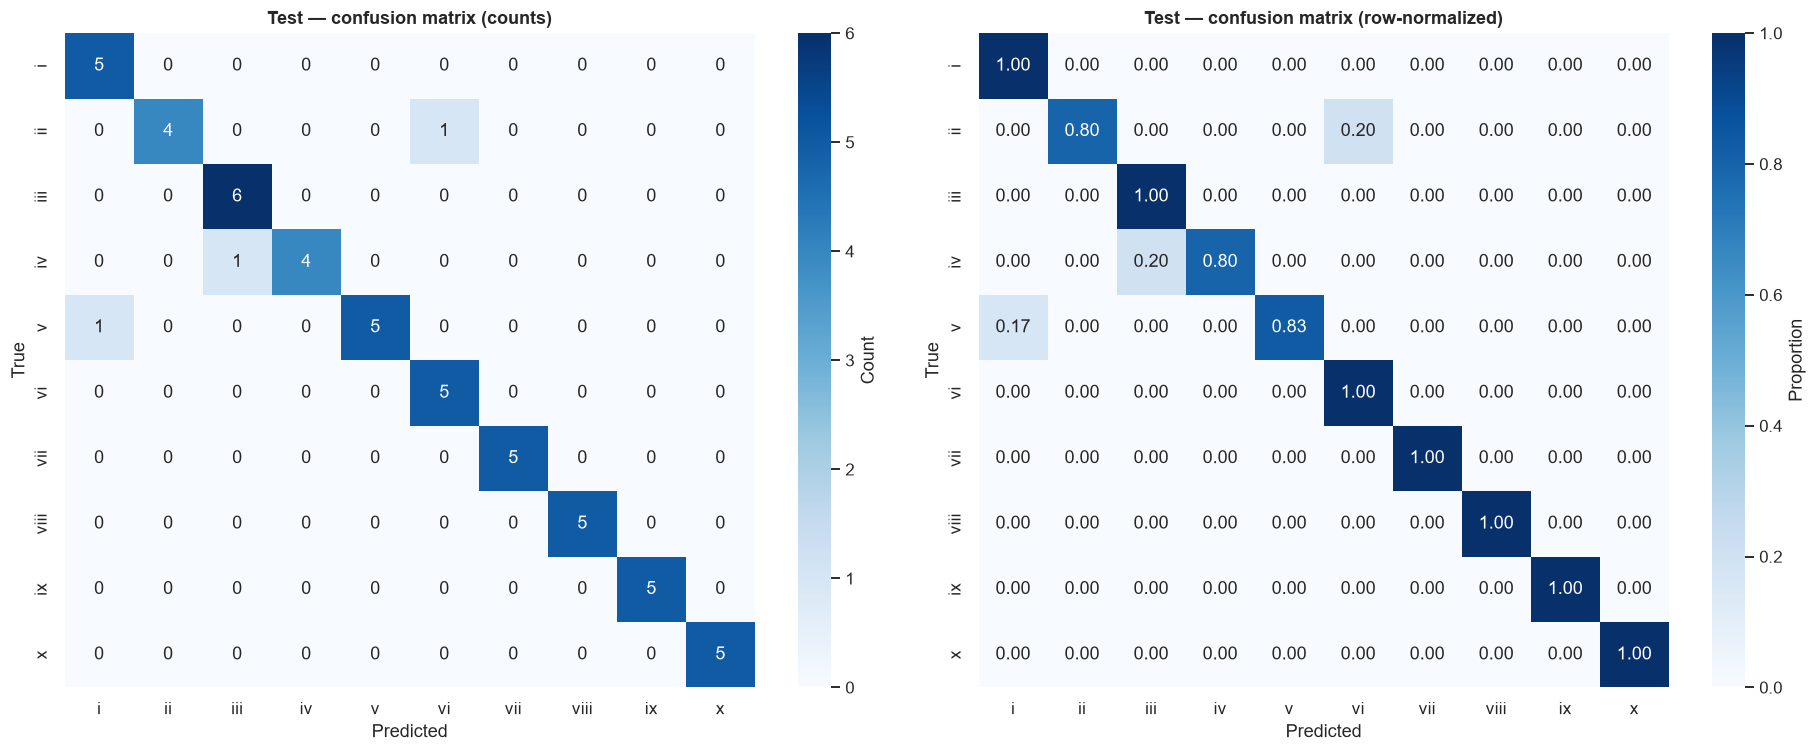


Đã lưu metrics + confusion matrix vào: c:\Users\Administrator\Downloads\deeplearningai-data-centric-competition-main\deeplearningai-data-centric-competition-main\reports\test_eval


In [28]:
# =============================================================================
# METRICS + CLASSIFICATION REPORT + CONFUSION MATRIX
# =============================================================================
def ece_score(y_true, probs, n_bins=10):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    correct = (pred == y_true).astype(np.float32)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() > 0:
            ece += mask.mean() * abs(correct[mask].mean() - conf[mask].mean())
    return float(ece)


eval_metrics = {
    "accuracy": float(accuracy_score(eval_true, eval_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(eval_true, eval_pred)),
    "macro_f1": float(f1_score(eval_true, eval_pred, average="macro", zero_division=0)),
    "weighted_f1": float(f1_score(eval_true, eval_pred, average="weighted", zero_division=0)),
    "top2_accuracy": float(top_k_accuracy_score(
        eval_true, eval_probs, k=min(2, num_eval_classes),
        labels=np.arange(num_eval_classes)
    )),
    "log_loss": float(log_loss(eval_true, eval_probs, labels=np.arange(num_eval_classes))),
    "ECE": ece_score(eval_true, eval_probs),
    "num_test_images": int(len(eval_df)),
    "num_errors": int((~eval_correct).sum()),
}

print("=" * 68)
print("KẾT QUẢ TEST ĐÁNH GIÁ")
print("=" * 68)
display(pd.DataFrame([eval_metrics]).T.rename(columns={0: "value"}).round(4))

print("\nClassification report:")
print(classification_report(
    eval_true, eval_pred,
    labels=np.arange(num_eval_classes),
    target_names=eval_class_names,
    digits=4,
    zero_division=0,
))

precision, recall, f1, support = precision_recall_fscore_support(
    eval_true, eval_pred, labels=np.arange(num_eval_classes), zero_division=0
)
per_class_df = pd.DataFrame({
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "support": support,
}, index=eval_class_names)

print("\nPer-class metrics:")
display(per_class_df.round(3))

per_class_df.to_csv(EVAL_REPORT_DIR / "per_class_metrics.csv")
pd.DataFrame([eval_metrics]).to_csv(EVAL_REPORT_DIR / "metrics.csv", index=False)

cm = confusion_matrix(eval_true, eval_pred, labels=np.arange(num_eval_classes))
with np.errstate(divide="ignore", invalid="ignore"):
    cm_norm = np.nan_to_num(cm / cm.sum(axis=1, keepdims=True))

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=eval_class_names, yticklabels=eval_class_names,
    cbar_kws={"label": "Count"}, ax=axes[0],
)
axes[0].set_title("Test — confusion matrix (counts)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

sns.heatmap(
    cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
    xticklabels=eval_class_names, yticklabels=eval_class_names,
    cbar_kws={"label": "Proportion"}, ax=axes[1],
)
axes[1].set_title("Test — confusion matrix (row-normalized)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.tight_layout()
plt.savefig(EVAL_REPORT_DIR / "confusion_matrix.png", bbox_inches="tight")
plt.show()

pd.DataFrame(cm, index=eval_class_names, columns=eval_class_names).to_csv(
    EVAL_REPORT_DIR / "confusion_matrix.csv"
)

with open(EVAL_REPORT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(eval_metrics, f, indent=2, ensure_ascii=False)

print("\nĐã lưu metrics + confusion matrix vào:", EVAL_REPORT_DIR)

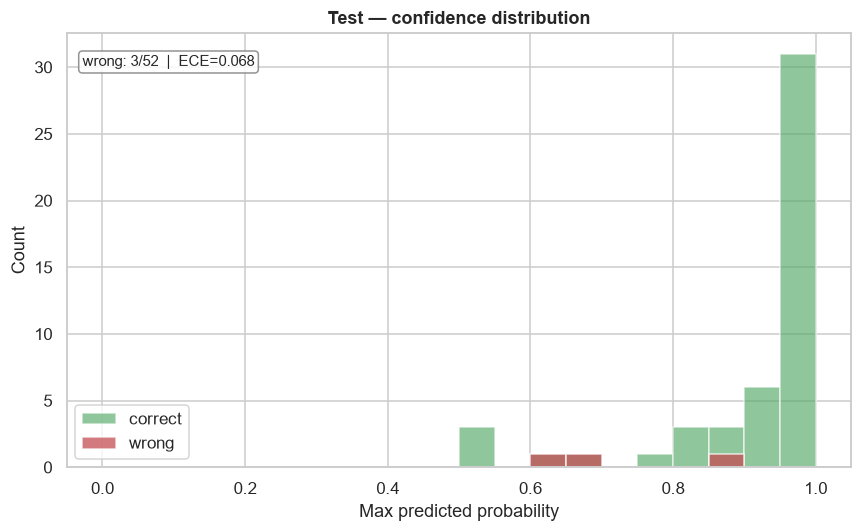

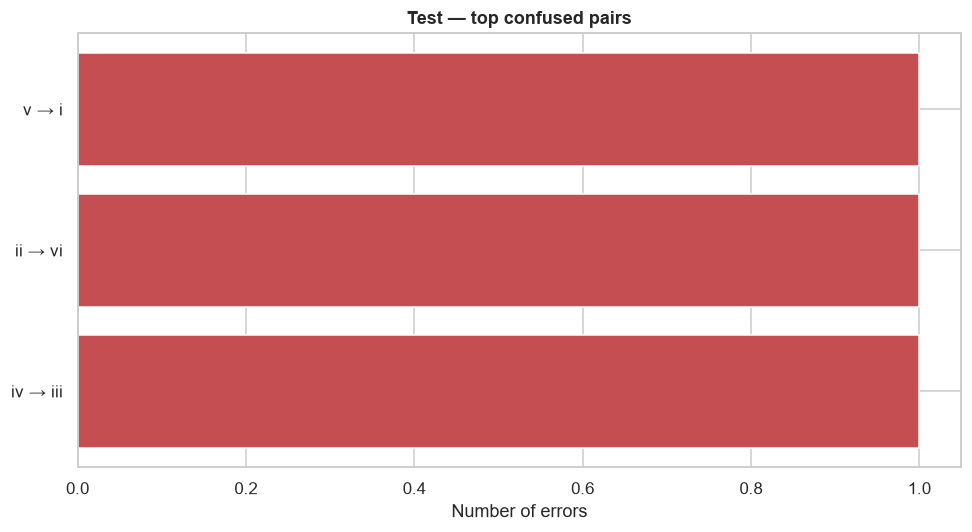

,true,predicted,count
0,v,i,1
1,ii,vi,1
2,iv,iii,1


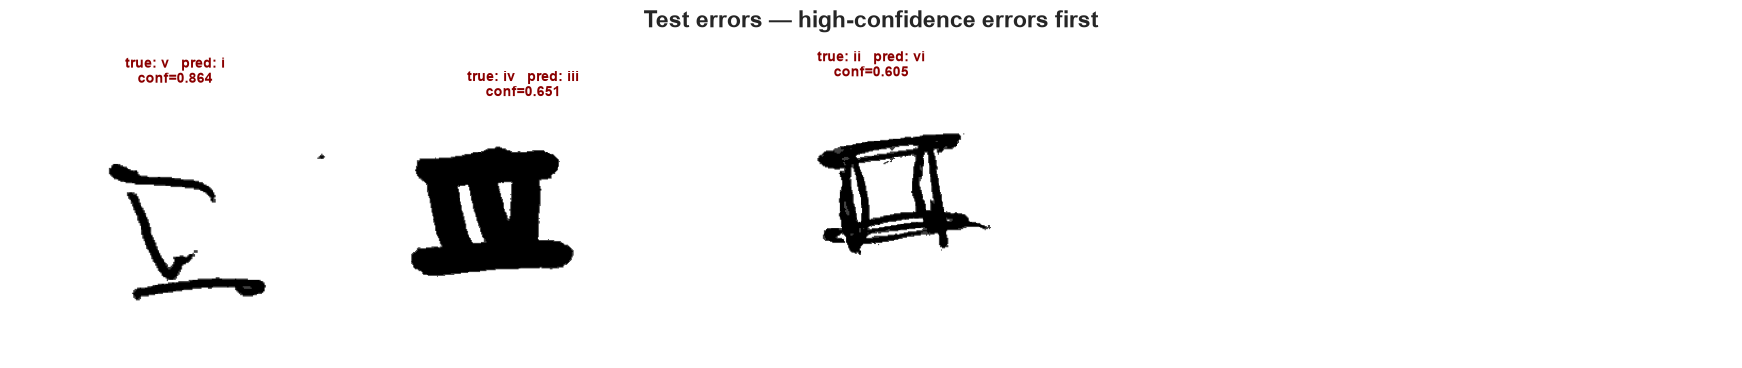


Các file test report:
  - confidence_distribution.png
  - confusion_matrix.csv
  - confusion_matrix.png
  - errors_gallery.png
  - metrics.csv
  - metrics.json
  - per_class_metrics.csv
  - predictions.csv
  - top_confused_pairs.csv
  - top_confused_pairs.png


,path,true,predicted,confidence,correct,p_i,p_ii,p_iii,p_iv,p_v,p_vi,p_vii,p_viii,p_ix,p_x
23,C:\Users\Administrator\Downloads\deeplearninga...,v,i,0.864064,False,0.864064,0.016606,0.007036,0.002389,0.014216,0.025966,0.006201,0.007734,0.008318,0.047470
18,C:\Users\Administrator\Downloads\deeplearninga...,iv,iii,0.651192,False,0.010549,0.011986,0.651192,0.223348,0.005758,0.029211,0.004274,0.034136,0.022054,0.007492
7,C:\Users\Administrator\Downloads\deeplearninga...,ii,vi,0.605220,False,0.014993,0.115944,0.055253,0.009968,0.046883,0.605220,0.107472,0.014310,0.015032,0.014926
48,C:\Users\Administrator\Downloads\deeplearninga...,x,x,0.988176,True,0.000369,0.001768,0.000558,0.001149,0.002606,0.001162,0.000471,0.001420,0.002321,0.988176
37,C:\Users\Administrator\Downloads\deeplearninga...,viii,viii,0.987504,True,0.000943,0.002068,0.000486,0.002573,0.001260,0.000931,0.000319,0.987504,0.002074,0.001842
9,C:\Users\Administrator\Downloads\deeplearninga...,ii,ii,0.986852,True,0.004146,0.986852,0.002624,0.000246,0.001319,0.001103,0.001022,0.000755,0.001224,0.000709
11,C:\Users\Administrator\Downloads\deeplearninga...,iii,iii,0.986579,True,0.000823,0.002097,0.986579,0.001343,0.000480,0.000602,0.000341,0.006601,0.000169,0.000965
39,C:\Users\Administrator\Downloads\deeplearninga...,viii,viii,0.985993,True,0.000650,0.001543,0.000282,0.003465,0.000614,0.001082,0.000083,0.985993,0.004862,0.001427
35,C:\Users\Administrator\Downloads\deeplearninga...,vii,vii,0.984847,True,0.000624,0.001016,0.001266,0.000255,0.001442,0.005723,0.984847,0.003709,0.000482,0.000636
34,C:\Users\Administrator\Downloads\deeplearninga...,vii,vii,0.984766,True,0.000774,0.001982,0.001589,0.000153,0.001417,0.002786,0.984766,0.005142,0.000512,0.000879


In [29]:
# =============================================================================
# PHÂN TÍCH LỖI: confidence, top confused pairs, gallery ảnh sai, CSV dự đoán
# =============================================================================
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.linspace(0.0, 1.0, 21)
ax.hist(eval_conf[eval_correct], bins=bins, alpha=0.65, label="correct", color="#55A868")
ax.hist(eval_conf[~eval_correct], bins=bins, alpha=0.75, label="wrong", color="#C44E52")
ax.set_title("Test — confidence distribution")
ax.set_xlabel("Max predicted probability")
ax.set_ylabel("Count")
ax.legend()
ax.text(
    0.02, 0.95,
    f"wrong: {int((~eval_correct).sum())}/{len(eval_correct)}  |  ECE={eval_metrics['ECE']:.3f}",
    transform=ax.transAxes, va="top", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="gray", alpha=0.85),
)
plt.tight_layout()
plt.savefig(EVAL_REPORT_DIR / "confidence_distribution.png", bbox_inches="tight")
plt.show()

off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
flat_idx = np.argsort(off_diag.ravel())[::-1][:10]
pair_rows = []
for idx in flat_idx:
    i, j = np.unravel_index(idx, off_diag.shape)
    if off_diag[i, j] > 0:
        pair_rows.append({
            "true": eval_class_names[i],
            "predicted": eval_class_names[j],
            "count": int(off_diag[i, j]),
        })
pairs_df = pd.DataFrame(pair_rows)

if len(pairs_df):
    fig, ax = plt.subplots(figsize=(9, 5))
    labels = [f"{r.true} → {r.predicted}" for r in pairs_df.itertuples()]
    ax.barh(labels[::-1], pairs_df["count"].values[::-1], color="#C44E52")
    ax.set_title("Test — top confused pairs")
    ax.set_xlabel("Number of errors")
    plt.tight_layout()
    plt.savefig(EVAL_REPORT_DIR / "top_confused_pairs.png", bbox_inches="tight")
    plt.show()
    display(pairs_df)
    pairs_df.to_csv(EVAL_REPORT_DIR / "top_confused_pairs.csv", index=False)
else:
    print("Không có cặp lớp nào bị nhầm.")


def show_eval_errors(frame, probs, n=20, fname="errors_gallery.png"):
    true = frame["label"].values
    pred = probs.argmax(axis=1)
    conf = probs.max(axis=1)
    indices = np.where(pred != true)[0]
    if len(indices) == 0:
        print("Không có ảnh dự đoán sai.")
        return
    indices = indices[np.argsort(-conf[indices])][:n]

    n_cols = 5
    n_rows = int(np.ceil(len(indices) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 3.4 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, idx in zip(axes, indices):
        with Image.open(frame.iloc[idx]["path"]) as im:
            ax.imshow(im.convert("L"), cmap="gray")
        ax.axis("off")
        ax.set_title(
            f"true: {eval_class_names[true[idx]]}   pred: {eval_class_names[pred[idx]]}\n"
            f"conf={conf[idx]:.3f}",
            fontsize=9, color="darkred",
        )
    for ax in axes[len(indices):]:
        ax.axis("off")
    fig.suptitle("Test errors — high-confidence errors first", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(EVAL_REPORT_DIR / fname, bbox_inches="tight")
    plt.show()


show_eval_errors(eval_df, eval_probs, n=20)

pred_table = pd.DataFrame({
    "path": eval_df["path"].values,
    "true": [eval_class_names[i] for i in eval_true],
    "predicted": [eval_class_names[i] for i in eval_pred],
    "confidence": eval_conf,
    "correct": eval_correct,
})
for i, class_name in enumerate(eval_class_names):
    pred_table[f"p_{class_name}"] = eval_probs[:, i]

pred_table = pred_table.sort_values(["correct", "confidence"], ascending=[True, False])
pred_table.to_csv(EVAL_REPORT_DIR / "predictions.csv", index=False)

print("\nCác file test report:")
for path in sorted(EVAL_REPORT_DIR.glob("*")):
    print("  -", path.name)

display(pred_table.head(15))

## 16. Checklist cải thiện (data-centric)

### Nếu accuracy còn thấp
1. **Xem confusion matrix**: cặp nào sai nhiều nhất? Bổ sung ảnh đúng cặp đó.
2. **Xem ảnh lỗi confidence cao**: rất có thể nhãn sai hoặc ảnh quá mờ/nhiễu.
3. **Xem Grad-CAM**: nếu model nhìn nền/viền, hãy crop sát nét chữ hoặc thêm ảnh nền đa dạng.
4. **Kiểm tra class imbalance**: notebook đã dùng class weights.
5. **Kiểm tra trùng lặp/leakage**: notebook đã loại theo MD5; nên kiểm tra thêm near-duplicate.

### Vì label_book chỉ có 52 ảnh
- Accuracy test dao động rất mạnh: 1 ảnh = ~1.9%.
- Nên chạy **stratified k-fold cross-validation** trên train+val để có khoảng tin cậy.
- Dùng label_book để kiểm tra thủ công từng lỗi, không nên coi là thước đo duy nhất.

### Augmentation & training
- Không bao giờ flip ảnh chữ số La Mã.
- Thử `IMG_SIZE=96` nếu GPU/CPU chậm; `160` hoặc `224` nếu VRAM đủ.
- Nếu overfit: tăng dropout/augmentation, hoặc freeze nhiều layer hơn.
- Nếu underfit: mở thêm `block4` (`features[17:]`), tăng epoch phase 2.
- Có thể thử test-time augmentation (xoay ±5°, zoom nhẹ — không flip) và lấy trung bình xác suất.
- Bật `MIXED_PRECISION=True` trên GPU để tăng tốc.

### Data-centric nâng cao
- Sửa nhãn sai là cách tăng điểm nhanh nhất. Ưu tiên ảnh sai confidence cao.
- Thêm ảnh cho các cặp dễ nhầm: `ii/iii`, `vii/viii`, `iv/vi`, `ix/x`.
- Chuẩn hoá cách chụp: cùng độ phân giải, độ tương phản, kiểu nền.
- Loại ảnh ngoại lai: nét chữ quá nhỏ, bị cắt, nhãn không rõ.
- Calibration nếu cần xác suất đáng tin: temperature scaling trên validation.
- Sau mỗi thay đổi dataset, chạy lại notebook và so sánh `metrics_summary.csv`, confusion matrix, danh sách lỗi — đừng chỉ nhìn accuracy.

### Gợi ý đọc kết quả
- `accuracy` cao nhưng `balanced_accuracy` thấp → model bỏ rơi lớp ít ảnh.
- `val` tốt nhưng `test` tệ → domain shift hoặc test quá nhỏ.
- `ECE` cao → model tự tin quá mức; cần calibration hoặc thêm dữ liệu khó.
- `top2_accuracy` cao hơn nhiều `accuracy` → lỗi chủ yếu giữa 2 lớp gần nhau.